# Comprensión de los datos (EDA) - Riesgo de crédito

**Objetivo del proyecto:** construir un modelo predictivo que, a partir de información histórica de créditos, anticipe si un nuevo cliente pagará a tiempo (`Pago_atiempo`).

**Objetivo de este notebook:** entender la estructura, la calidad y las relaciones de los datos antes de la ingeniería de características (`ft_engineering.py`) y del entrenamiento (`model_training_evaluation.py`).

**Contenido:**

1. **Paso 1. Exploración inicial de datos:** estructura, tipos, faltantes, duplicados, target, estadísticos básicos y consistencia.
2. **Paso 2. Exploración de datos y descripción (EDA):**
   - 2.0 Preparación
   - 2.1 Análisis univariable
   - 2.2 Análisis bivariable
   - 2.3 Análisis multivariable
   - 2.4 Hallazgos clave e implicaciones para el modelado

In [1]:
# Importar dependencias y configurar visualización
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

# Raíz del repo: primera carpeta (actual o superior) que contiene requirements.txt
project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
csv_path = project_root / "Base_de_datos.csv"

target = "Pago_atiempo"

# Semilla única para todos los muestreos y algoritmos aleatorios
SEMILLA = 42

Se importan en una sola celda todas las librerías del notebook:

- `pandas` y `numpy` para manipular los datos.
- `matplotlib` y `seaborn` para los gráficos.
- `scipy.stats` para las pruebas estadísticas.
- `scikit-learn` para el cálculo del VIF (multicolinealidad).

También se configura la visualización y se define la ruta al CSV generado en `cargar_datos.ipynb`. La variable objetivo es `Pago_atiempo`. La constante `SEMILLA` fija la aleatoriedad de los muestreos para que los resultados sean reproducibles.

## Paso 1: Exploración inicial de datos

Objetivo: conocer la estructura del dataset (tamaño, tipos de datos, nulos, duplicados, cardinalidad, variable objetivo y estadísticos básicos) antes de cualquier limpieza o transformación.

In [2]:
# Cargar el dataset
df = pd.read_csv(csv_path)

print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dimensiones: 10,763 filas x 23 columnas


Se carga `Base_de_datos.csv` y se reporta el tamaño del dataset.

In [3]:
# Primeras y últimas filas
display(df.head())
display(df.tail())

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,7,2024-12-21 11:31:35,"3,692,160.00",10,42,Independiente,8000000,2500000,341296,88.77,695.00,10,5,0.00,"51,258.00","51,258.00",0.00,5,0,0,"908,526.00",Estable,1
1,4,2025-04-22 09:47:35,"840,000.00",6,60,Empleado,3000000,2000000,124876,95.23,789.00,3,1,0.00,"8,673.00","8,673.00",0.00,0,0,2,"939,017.00",Creciente,1
2,9,2026-01-08 12:22:40,"5,974,028.40",10,36,Independiente,4036000,829000,529554,47.61,740.00,4,5,0.00,"18,702.00","18,702.00",0.00,3,0,0,NaN,NaN,0
3,4,2025-08-04 12:04:10,"1,671,240.00",6,48,Empleado,1524547,498000,252420,95.23,837.00,4,4,0.00,"15,782.00","15,782.00",0.00,3,0,0,"1,536,193.00",Creciente,1
4,9,2025-04-26 11:24:26,"2,781,636.00",11,44,Empleado,5000000,4000000,217037,95.23,771.00,4,6,0.00,"204,804.00","204,804.00",0.00,3,0,1,"933,473.00",Creciente,1


,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
10758,9,2025-01-19 16:18:28,"2,414,886.00",10,29,Independiente,3000000,300000,204819,13.13,747.00,2,2,172.00,"1,112.00","1,112.00",NaN,0,0,1,NaN,NaN,0
10759,4,2025-01-10 16:40:21,"2,916,000.00",24,27,Empleado,2500000,400000,127460,55.97,714.00,5,4,0.00,"9,771.00","9,771.00",0.00,1,0,4,"1,958,333.00",Creciente,0
10760,4,2025-06-19 14:28:47,"4,249,200.00",36,24,Empleado,2000000,500000,140042,47.61,807.00,2,2,0.00,"1,603.00","1,603.00",0.00,1,0,0,"998,859.00",Creciente,0
10761,9,2025-03-02 11:53:41,"1,283,307.60",10,26,Empleado,1500000,600000,108958,42.89,755.00,5,3,0.00,"8,488.00","8,488.00",0.00,2,0,3,NaN,NaN,0
10762,4,2024-12-08 12:46:03,"3,915,000.00",12,24,Independiente,4000000,2000000,306174,59.32,716.00,9,7,0.00,"5,046.00","5,046.00",0.00,2,1,1,NaN,NaN,0


Se revisan las primeras y últimas filas para tener una idea visual del contenido de cada columna y detectar valores extraños a simple vista.

In [4]:
# Tipos de datos y valores no nulos por columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

`df.info()` muestra el tipo de dato inferido y el conteo de valores no nulos. Hay que validar que cada tipo corresponda con el significado de la variable. Aparecen dos diferencias:

- `fecha_prestamo` se lee como texto y no como fecha.
- `tipo_credito` se lee como entero, aunque es un código categórico.

In [5]:
# Resumen por columna: tipo, nulos, % nulos y cardinalidad
resumen_columnas = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(),
    "ejemplo": df.iloc[0],
}).sort_values("pct_nulos", ascending=False)

resumen_columnas

,dtype,nulos,pct_nulos,valores_unicos,ejemplo
tendencia_ingresos,str,2932,27.24,46,Estable
promedio_ingresos_datacredito,float64,2930,27.22,5309,"908,526.00"
saldo_mora_codeudor,float64,590,5.48,4,0.00
saldo_principal,float64,405,3.76,8647,"51,258.00"
saldo_total,float64,156,1.45,8858,"51,258.00"
saldo_mora,float64,156,1.45,55,0.00
puntaje_datacredito,float64,6,0.06,315,695.00
tipo_credito,int64,0,0.00,6,7
huella_consulta,int64,0,0.00,28,5
creditos_sectorReal,int64,0,0.00,24,0


Tabla resumen de calidad por columna. Permite identificar de un vistazo:

- Qué variables tienen datos faltantes.
- Cuáles tienen baja cardinalidad (candidatas a categóricas).
- Cuáles tienen cardinalidad muy alta (fechas o variables continuas).

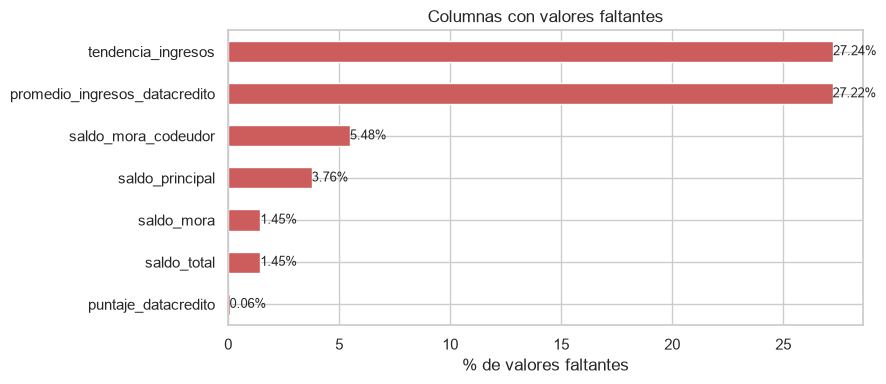

In [6]:
# Porcentaje de valores faltantes por columna
pct_nulos = resumen_columnas.loc[resumen_columnas["nulos"] > 0, "pct_nulos"].sort_values()

fig, eje = plt.subplots(figsize=(9, 4))
pct_nulos.plot.barh(ax=eje, color="indianred")
eje.bar_label(eje.containers[0], fmt="%.2f%%", fontsize=9)
eje.set_xlabel("% de valores faltantes")
eje.set_title("Columnas con valores faltantes")
plt.tight_layout()
plt.show()

Visualización de las columnas con faltantes. Destacan `promedio_ingresos_datacredito` y `tendencia_ingresos`, con más de una cuarta parte de los registros vacíos. Ambas describen los ingresos del cliente y tienen casi el mismo número de faltantes (2,930 y 2,932), lo que sugiere que faltan en los mismos clientes. Se verifica a continuación.

In [7]:
# ¿Los faltantes de Datacrédito coinciden en los mismos registros?
faltantes_datacredito = pd.crosstab(
    df["promedio_ingresos_datacredito"].isna().rename("sin_promedio_ingresos"),
    df["tendencia_ingresos"].isna().rename("sin_tendencia_ingresos"),
)
faltantes_datacredito

sin_tendencia_ingresos,False,True
sin_promedio_ingresos,,
False,7831,2
True,0,2930


Tabla cruzada de faltantes entre las dos variables de ingresos. Los nulos coinciden casi por completo: en 2,930 registros faltan ambas a la vez, en 2 falta solo `tendencia_ingresos` y en ninguno falta solo `promedio_ingresos_datacredito`. El faltante no es aleatorio: corresponde a clientes para los que no hay información de ingresos en Datacrédito.

In [8]:
# Filas duplicadas
n_duplicados = df.duplicated().sum()
print(f"Filas duplicadas: {n_duplicados}")

Filas duplicadas: 0


Se verifica si existen registros completamente duplicados, que podrían sesgar el entrenamiento del modelo.

In [9]:
# Distribución de la variable objetivo
distribucion_target = pd.DataFrame({
    "conteo": df[target].value_counts(),
    "porcentaje": (df[target].value_counts(normalize=True) * 100).round(2),
})
distribucion_target

,conteo,porcentaje
Pago_atiempo,,
1,10252,95.25
0,511,4.75


Se analiza el balance de `Pago_atiempo` (1 = pagó a tiempo, 0 = no pagó a tiempo). El 95.25% de los clientes pagó a tiempo y solo el 4.75% (511 casos) no lo hizo. Un desbalance tan fuerte implica que la *accuracy* no será una buena métrica. Habrá que usar métricas como recall, F1 o AUC, y considerar técnicas de balanceo.

In [10]:
# Separar columnas por tipo inferido por pandas
columnas_numericas = df.select_dtypes(include=np.number).columns.drop(target).tolist()
columnas_categoricas = df.select_dtypes(exclude=np.number).columns.tolist()

print(f"Numéricas ({len(columnas_numericas)}): {columnas_numericas}\n")
print(f"No numéricas ({len(columnas_categoricas)}): {columnas_categoricas}")

Numéricas (19): ['tipo_credito', 'capital_prestado', 'plazo_meses', 'edad_cliente', 'salario_cliente', 'total_otros_prestamos', 'cuota_pactada', 'puntaje', 'puntaje_datacredito', 'cant_creditosvigentes', 'huella_consulta', 'saldo_mora', 'saldo_total', 'saldo_principal', 'saldo_mora_codeudor', 'creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal', 'promedio_ingresos_datacredito']

No numéricas (3): ['fecha_prestamo', 'tipo_laboral', 'tendencia_ingresos']


Se separan las columnas según el tipo que infiere pandas.


In [11]:
# Estadísticos descriptivos de las variables numéricas
df[columnas_numericas].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
tipo_credito,"10,763.00",5.41,2.34,4.00,4.00,4.00,4.00,9.00,10.00,68.00
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","468,476.78","1,224,831.00","1,921,920.00","3,084,840.00","8,881,109.76","41,444,152.80"
plazo_meses,"10,763.00",10.58,6.63,2.00,2.00,6.00,10.00,12.00,36.00,90.00
edad_cliente,"10,763.00",43.95,15.06,19.00,22.00,33.00,42.00,53.00,122.00,123.00
salario_cliente,"10,763.00","17,216,431.46","355,476,717.60",0.00,"954,263.00","2,000,000.00","3,000,000.00","4,875,808.00","39,553,562.18","22,000,000,000.00"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,0.00,"500,000.00","1,000,000.00","2,000,000.00","17,946,060.00","6,787,675,263.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","51,439.94","121,041.50","182,863.00","287,833.50","1,114,004.42","3,816,752.00"
puntaje,"10,763.00",91.17,16.47,-38.01,-4.73,95.23,95.23,95.23,95.23,95.23
puntaje_datacredito,"10,757.00",780.79,104.88,-7.00,0.00,757.00,791.00,825.00,900.00,999.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,0.00,3.00,5.00,8.00,19.00,62.00


Se calculan media, desviación, mínimo, máximo y percentiles, incluidos p1 y p99. Comparar el p99 con el máximo permite detectar rangos imposibles y posibles outliers:

- `salario_cliente` tiene un p99 de alrededor de 39.6 millones, pero un máximo de 22,000 millones, y `total_otros_prestamos` pasa de un p99 de 17.9 millones a un máximo de 6,788 millones.
- `edad_cliente` tiene un p99 de 122 y un máximo de 123 años: más del 1% de los clientes tiene una edad imposible.
- `puntaje` (mínimo de -38.01) y `puntaje_datacredito` (mínimo de -7) tienen valores negativos.
- `plazo_meses` llega a 90 meses, con un p99 de 36.

Estos casos se cuantifican en los chequeos de consistencia más abajo.

In [12]:
# Frecuencias de las variables no numéricas y códigos categóricos
for columna in ["tipo_laboral", "tendencia_ingresos", "tipo_credito"]:
    print(f"--- {columna} ---")
    print(df[columna].value_counts(dropna=False).head(10))
    print()

--- tipo_laboral ---
tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64

--- tendencia_ingresos ---
tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
Name: count, dtype: int64

--- tipo_credito ---
tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64



Se revisan las categorías de las variables cualitativas para detectar categorías inválidas, poco frecuentes o mal escritas. Se muestran hasta 10 por columna, incluidos los nulos.

In [13]:
# Rango temporal de los préstamos
fechas = pd.to_datetime(df["fecha_prestamo"], errors="coerce")

print(f"Fechas no parseables: {fechas.isna().sum()}")
print(f"Desde: {fechas.min()}  |  Hasta: {fechas.max()}")
fechas.dt.to_period("M").value_counts().sort_index()

Fechas no parseables: 0
Desde: 2024-11-26 09:17:04  |  Hasta: 2026-04-26 18:43:52


fecha_prestamo
2024-11     186
2024-12    1216
2025-01    1917
2025-02    1094
2025-03    1115
2025-04    1102
2025-05    1083
2025-06     665
2025-07     644
2025-08     555
2025-09     361
2025-10     231
2025-11     166
2025-12     174
2026-01     127
2026-02      76
2026-03      40
2026-04      11
Freq: M, Name: count, dtype: int64

Se convierte `fecha_prestamo` a fecha (sin modificar `df`) para conocer la ventana temporal cubierta y el volumen de préstamos por mes. Esto es relevante para decidir si conviene un *split* temporal entre train y test.

In [14]:
# Chequeos rápidos de consistencia
valores_no_validos_tendencia = ~df["tendencia_ingresos"].isin(["Creciente", "Decreciente", "Estable"]) & df["tendencia_ingresos"].notna()

chequeos = {
    "edad_cliente > 100": (df["edad_cliente"] > 100).sum(),
    "edad_cliente < 18": (df["edad_cliente"] < 18).sum(),
    "puntaje_datacredito > 950": (df["puntaje_datacredito"] > 950).sum(),
    "puntaje < 0": (df["puntaje"] < 0).sum(),
    "salario_cliente <= 0": (df["salario_cliente"] <= 0).sum(),
    "capital_prestado <= 0": (df["capital_prestado"] <= 0).sum(),
    "cuota_pactada > salario_cliente": (df["cuota_pactada"] > df["salario_cliente"]).sum(),
    "tendencia_ingresos con valor no categórico": valores_no_validos_tendencia.sum(),
}
pd.Series(chequeos, name="registros").to_frame()

,registros
edad_cliente > 100,150
edad_cliente < 18,0
puntaje_datacredito > 950,6
puntaje < 0,135
salario_cliente <= 0,24
capital_prestado <= 0,0
cuota_pactada > salario_cliente,35
tendencia_ingresos con valor no categórico,58


Se cuentan los registros que violan reglas de negocio básicas:

- Edades imposibles.
- Puntajes fuera de rango.
- Montos no positivos.
- Cuota mayor al salario.
- Valores numéricos dentro de una variable categórica.


In [15]:
# ¿Las edades imposibles coinciden con los clientes sin puntaje en Datacrédito?
edad_imposible = df["edad_cliente"] > 100
display(pd.crosstab(edad_imposible.rename("edad_cliente > 100"),
                    (df["puntaje_datacredito"] <= 0).rename("puntaje_datacredito <= 0")))
display(df.loc[edad_imposible, "edad_cliente"].value_counts().rename("registros").to_frame())
df.loc[edad_imposible, ["puntaje_datacredito", "huella_consulta", "cant_creditosvigentes",
                        "promedio_ingresos_datacredito"]].describe().T

puntaje_datacredito <= 0,False,True
edad_cliente > 100,,
False,10612,1
True,5,145


,registros
edad_cliente,
122,144
121,4
123,2


,count,mean,std,min,25%,50%,75%,max
puntaje_datacredito,147.00,10.37,88.64,0.00,0.00,0.00,0.00,774.00
huella_consulta,150.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
cant_creditosvigentes,150.00,0.03,0.41,0.00,0.00,0.00,0.00,5.00
promedio_ingresos_datacredito,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Se cruzan las dos anomalías más llamativas: edades mayores a 100 años y `puntaje_datacredito` menor o igual a 0. De los 150 clientes con más de 100 años, 145 tienen además un `puntaje_datacredito` menor o igual a 0. Todos tienen una edad de 121, 122 o 123 años, y prácticamente ninguno registra consultas, créditos vigentes ni ingresos en Datacrédito.

No parecen errores aleatorios, sino **valores por defecto que se asignan a clientes sin historial en la central de riesgo**. Por eso conviene tratarlos como un segmento propio (con una *flag* "sin historial") en lugar de imputarlos como outliers aislados.

### Hallazgos iniciales

- **Tamaño:** 10,763 registros y 23 columnas, sin filas duplicadas.
- **Target muy desbalanceado:** 95.25% pagó a tiempo y 4.75% no (511 casos). Habrá que usar métricas adecuadas (recall, F1, AUC-PR) y evaluar técnicas de balanceo.
- **Faltantes:**
  - `promedio_ingresos_datacredito` y `tendencia_ingresos` tienen alrededor de 27% de faltantes, y coinciden en los mismos clientes: en 2,930 registros faltan ambas a la vez, lo que apunta a clientes sin información de ingresos en Datacrédito.
  - `saldo_mora_codeudor` tiene 5.5%, `saldo_principal` 3.8%, `saldo_mora` y `saldo_total` 1.4%, y `puntaje_datacredito` solo 6 registros.
- **Tipos a corregir:** `fecha_prestamo` es texto (hay que convertirla a fecha) y `tipo_credito` es un código categórico guardado como entero.
- **Categorías sucias o raras:**
  - `tendencia_ingresos` tiene 58 valores numéricos mezclados con `Creciente`, `Decreciente` y `Estable`.
  - `tipo_credito` tiene categorías con muy pocos registros, como el código `68`, con un solo caso.
- **Valores atípicos o imposibles:**
  - 150 clientes con más de 100 años (entre 121 y 123) y 24 con salario menor o igual a 0.
  - Las edades imposibles coinciden casi por completo (145 de 150) con `puntaje_datacredito` menor o igual a 0: corresponden a clientes **sin historial en Datacrédito**, no a errores aislados.
  - 35 con una cuota mayor que el salario.
  - 135 registros con `puntaje` negativo y 6 con `puntaje_datacredito` mayor a 950.
  - Salarios y otros préstamos con máximos extremos.

**Siguiente paso:** el EDA, con análisis univariable, bivariable y multivariable.

## Paso 2: Exploración de datos y descripción (EDA)

Este paso se divide en análisis **univariable**, **bivariable** (cada variable frente a `Pago_atiempo`) y **multivariable**. Antes se prepara una copia del dataset con los tipos corregidos, solo para el análisis.

### 2.0 Preparación para el análisis

In [16]:
# Copia de trabajo con tipos corregidos (no modifica df ni el CSV)
df_eda = df.copy()

df_eda["fecha_prestamo"] = pd.to_datetime(df_eda["fecha_prestamo"])
df_eda["mes_prestamo"] = df_eda["fecha_prestamo"].dt.to_period("M")
df_eda["tipo_credito"] = df_eda["tipo_credito"].astype("category")

categorias_tendencia = ["Creciente", "Decreciente", "Estable"]
df_eda["tendencia_ingresos"] = df_eda["tendencia_ingresos"].where(
    df_eda["tendencia_ingresos"].isin(categorias_tendencia)
)

df_eda["impago"] = 1 - df_eda[target]
tasa_impago_global = df_eda["impago"].mean()

print(f"Valores inválidos de tendencia_ingresos pasados a NaN: {valores_no_validos_tendencia.sum()}")
print(f"Tasa de impago global: {tasa_impago_global:.2%}")

Valores inválidos de tendencia_ingresos pasados a NaN: 58
Tasa de impago global: 4.75%


Se trabaja sobre `df_eda`, una copia del dataset:

- `fecha_prestamo` pasa a fecha y se deriva `mes_prestamo`.
- `tipo_credito` pasa a categórica.
- Los valores numéricos de `tendencia_ingresos` se tratan como faltantes.
- Se crea `impago = 1 - Pago_atiempo` para leer directamente la **tasa de impago**.


In [17]:
# Clasificación de variables
variables_continuas = [
    "capital_prestado", "edad_cliente", "salario_cliente", "total_otros_prestamos",
    "cuota_pactada", "puntaje", "puntaje_datacredito", "saldo_mora", "saldo_total",
    "saldo_principal", "saldo_mora_codeudor", "promedio_ingresos_datacredito",
]
variables_discretas = [
    "plazo_meses", "cant_creditosvigentes", "huella_consulta",
    "creditos_sectorFinanciero", "creditos_sectorCooperativo", "creditos_sectorReal",
]
variables_categoricas = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]

variables_numericas = variables_continuas + variables_discretas
print(f"Continuas: {len(variables_continuas)} | Discretas: {len(variables_discretas)} | Categóricas: {len(variables_categoricas)}")

Continuas: 12 | Discretas: 6 | Categóricas: 3



- **Continuas:** montos, saldos, puntajes y edad.
- **Discretas:** plazos y conteos de créditos o consultas.
- **Categóricas:** `tipo_credito`, `tipo_laboral` y `tendencia_ingresos`. `tipo_credito` es un código, no una magnitud.

In [18]:
# Funciones auxiliares de graficación
def graficar_grilla(columnas, funcion_grafico, n_columnas=4, alto_fila=3, titulo=None):
    n_filas = int(np.ceil(len(columnas) / n_columnas))
    fig, ejes = plt.subplots(n_filas, n_columnas, figsize=(4.2 * n_columnas, alto_fila * n_filas))
    ejes = np.atleast_1d(ejes).flatten()
    for eje, columna in zip(ejes, columnas):
        funcion_grafico(columna, eje)
    for eje in ejes[len(columnas):]:
        eje.set_visible(False)
    if titulo:
        fig.suptitle(titulo, fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()


def serie_para_grafico(columna, columnas_log=()):
    serie = df_eda[columna].dropna()
    if columna in columnas_log:
        return np.log1p(serie), f"log1p({columna})"
    return serie, columna


def etiquetar_nulos(serie):
    return serie.astype(str).replace("nan", "Sin dato")

Se definen funciones reutilizables:

- `graficar_grilla`: dibuja varias variables en una misma figura.
- `serie_para_grafico`: devuelve la variable en escala original o, si se le indica, en escala `log1p`.
- `etiquetar_nulos`: muestra los faltantes como la categoría "Sin dato".

### 2.1 Análisis univariable

Se estudia cada variable de forma aislada: su distribución, su forma (asimetría y curtosis) y la presencia de outliers.

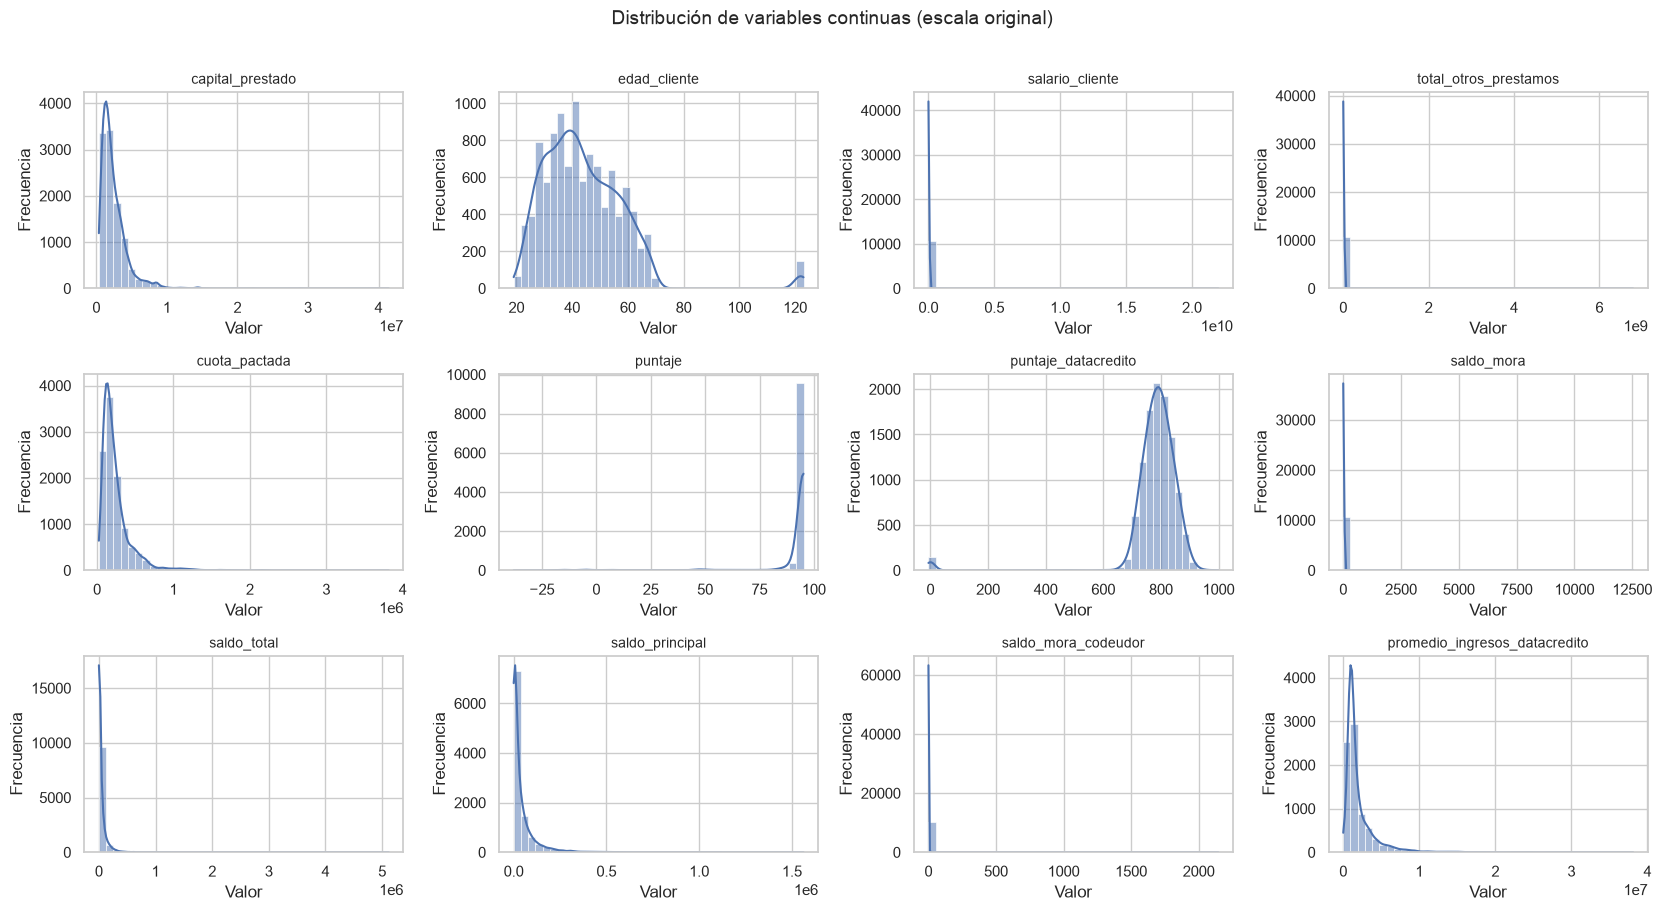

In [19]:
# Histogramas de las variables continuas en escala original
def histograma(columna, eje, columnas_log=()):
    serie, etiqueta = serie_para_grafico(columna, columnas_log)
    sns.histplot(serie, kde=True, bins=40, ax=eje)
    eje.set_title(etiqueta, fontsize=10)
    eje.set_xlabel("Valor (log1p)" if columna in columnas_log else "Valor")
    eje.set_ylabel("Frecuencia")


graficar_grilla(variables_continuas, histograma, titulo="Distribución de variables continuas (escala original)")

Histogramas con curva de densidad (KDE) en la escala original. En varias variables monetarias, unos pocos valores extremos estiran el eje X y concentran casi todos los registros en una sola barra cerca de 0. También aparecen dos grupos anómalos: clientes con edad cercana a 120 años y registros con `puntaje_datacredito` cerca de 0, separados del resto de la distribución.

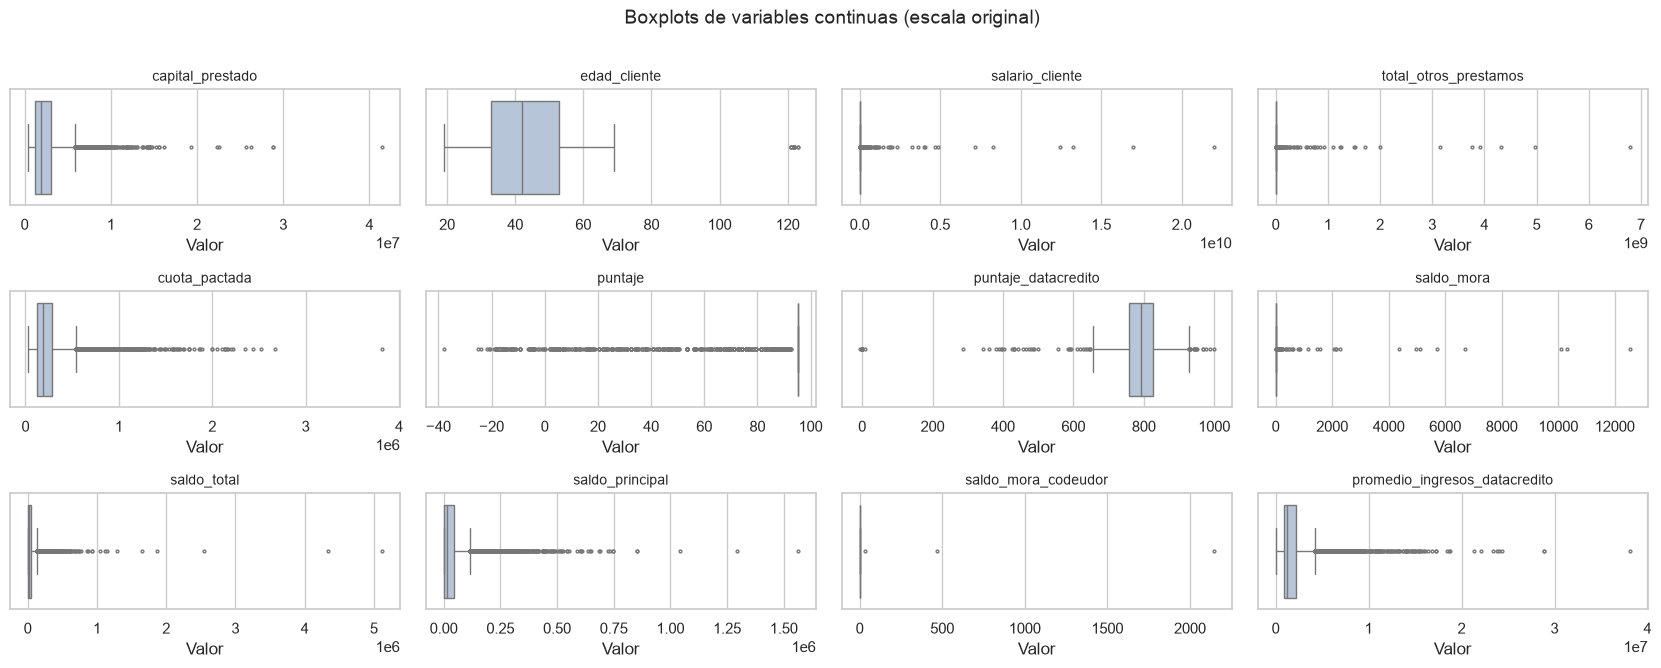

In [20]:
# Boxplots de las variables continuas en escala original
def boxplot_simple(columna, eje, columnas_log=()):
    serie, etiqueta = serie_para_grafico(columna, columnas_log)
    sns.boxplot(x=serie, ax=eje, color="lightsteelblue", flierprops={"markersize": 2})
    eje.set_title(etiqueta, fontsize=10)
    eje.set_xlabel("Valor (log1p)" if columna in columnas_log else "Valor")


graficar_grilla(variables_continuas, boxplot_simple, alto_fila=2.2,
                titulo="Boxplots de variables continuas (escala original)")

Los boxplots muestran mediana, rango intercuartílico (IQR) y valores atípicos. En la escala original, las cajas de las variables monetarias quedan comprimidas por los outliers.

In [21]:
# Forma de la distribución: asimetría, curtosis, % de outliers y % de ceros
def resumen_distribucion(serie):
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera_de_rango = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
    return pd.Series({
        "asimetria": serie.skew(),
        "curtosis": serie.kurt(),
        "pct_outliers_iqr": fuera_de_rango.mean() * 100,
        "pct_ceros": (serie == 0).mean() * 100,
    })


forma_distribucion = (
    df_eda[variables_numericas]
    .apply(resumen_distribucion)
    .T.sort_values("asimetria", key=abs, ascending=False)
)
forma_distribucion

,asimetria,curtosis,pct_outliers_iqr,pct_ceros
saldo_mora_codeudor,94.97,"9,279.82",0.03,99.97
salario_cliente,43.78,"2,211.23",6.67,0.22
saldo_mora,40.57,"1,845.71",0.52,99.48
total_otros_prestamos,38.46,"1,719.28",5.47,4.13
saldo_total,20.20,789.17,9.14,7.44
puntaje_datacredito,-5.64,39.44,1.82,1.35
saldo_principal,5.05,51.06,9.18,6.11
puntaje,-4.87,24.08,12.60,0.00
promedio_ingresos_datacredito,4.28,32.77,10.01,0.09
creditos_sectorCooperativo,4.22,29.35,17.61,82.39


Resumen cuantitativo de la forma de cada variable:

- **Asimetría (skew):** valores mayores a 1 en valor absoluto indican una distribución fuertemente sesgada.
- **Curtosis:** valores altos indican colas pesadas, es decir, valores extremos frecuentes.
- **% outliers (IQR):** proporción de registros fuera de $Q_1 - 1.5 \cdot IQR$ y $Q_3 + 1.5 \cdot IQR$.
- **% ceros:** las variables casi siempre en 0 aportan poca variabilidad.

In [22]:
# Criterio para identificar variables con sesgo positivo fuerte (candidatas a escala log1p)
umbral_asimetria = 2

forma_continuas = forma_distribucion.loc[variables_continuas]
es_sesgada = (forma_continuas["asimetria"] > umbral_asimetria) & (df_eda[variables_continuas].min() >= 0)
variables_sesgadas = forma_continuas.index[es_sesgada].tolist()

print(f"Variables con asimetría > {umbral_asimetria} y sin valores negativos ({len(variables_sesgadas)}):")
print(variables_sesgadas)

Variables con asimetría > 2 y sin valores negativos (9):
['capital_prestado', 'salario_cliente', 'total_otros_prestamos', 'cuota_pactada', 'saldo_mora', 'saldo_total', 'saldo_principal', 'saldo_mora_codeudor', 'promedio_ingresos_datacredito']


A partir de la tabla anterior se define qué variables continuas conviene ver en escala logarítmica. Deben cumplir dos condiciones:

- **Asimetría positiva mayor a 2:** cola larga hacia la derecha, que es la que la transformación `log1p` comprime.
- **Sin valores negativos:** `log1p` no está definida para valores menores a -1 y distorsiona los negativos.

El umbral de 2 es más exigente que la regla de 1 de la tabla anterior, para transformar solo las colas más extremas. Los puntajes quedan fuera porque su sesgo es negativo (cola hacia la izquierda). `edad_cliente` (1.93) está sesgada, pero queda bajo el umbral, y su sesgo se debe al grupo aislado de 121 a 123 años más que a una cola continua. El resultado son las variables monetarias: montos, saldos e ingresos.

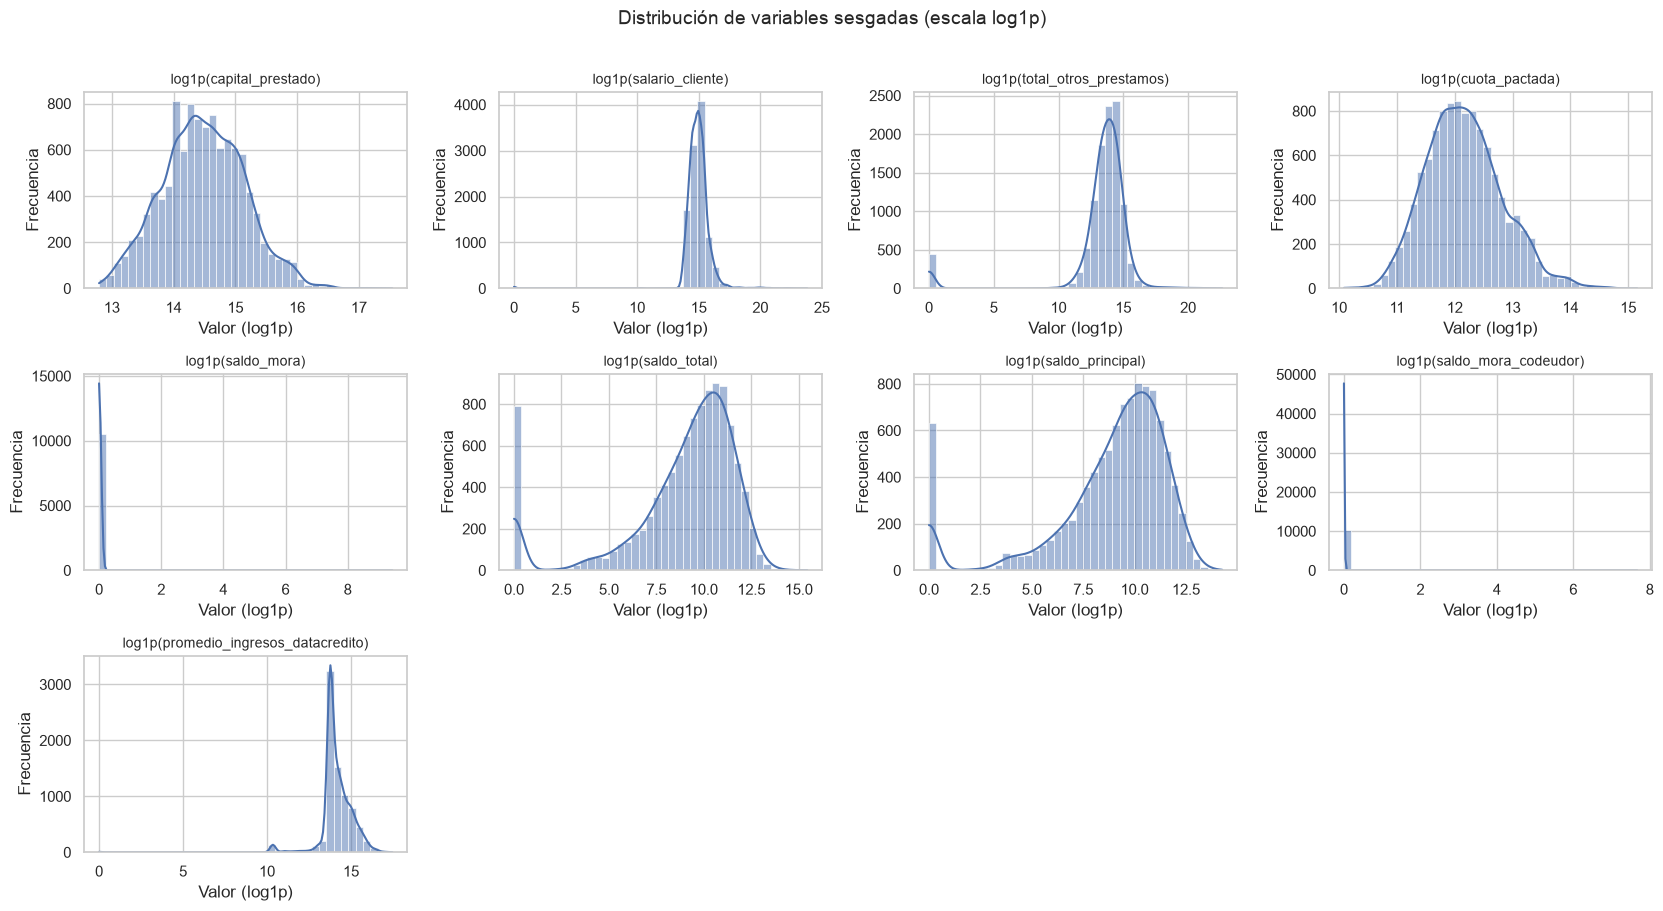

In [23]:
# Histogramas de las variables sesgadas en escala log1p
graficar_grilla(variables_sesgadas, lambda columna, eje: histograma(columna, eje, variables_sesgadas),
                titulo="Distribución de variables sesgadas (escala log1p)")

Con la escala `log1p`, las variables monetarias se pueden leer a pesar de sus colas largas: `capital_prestado`, `cuota_pactada` y `promedio_ingresos_datacredito` toman una forma cercana a la normal. `saldo_total`, `saldo_principal` y `total_otros_prestamos` muestran un pico separado en 0, que corresponde a clientes sin saldo u otras deudas.

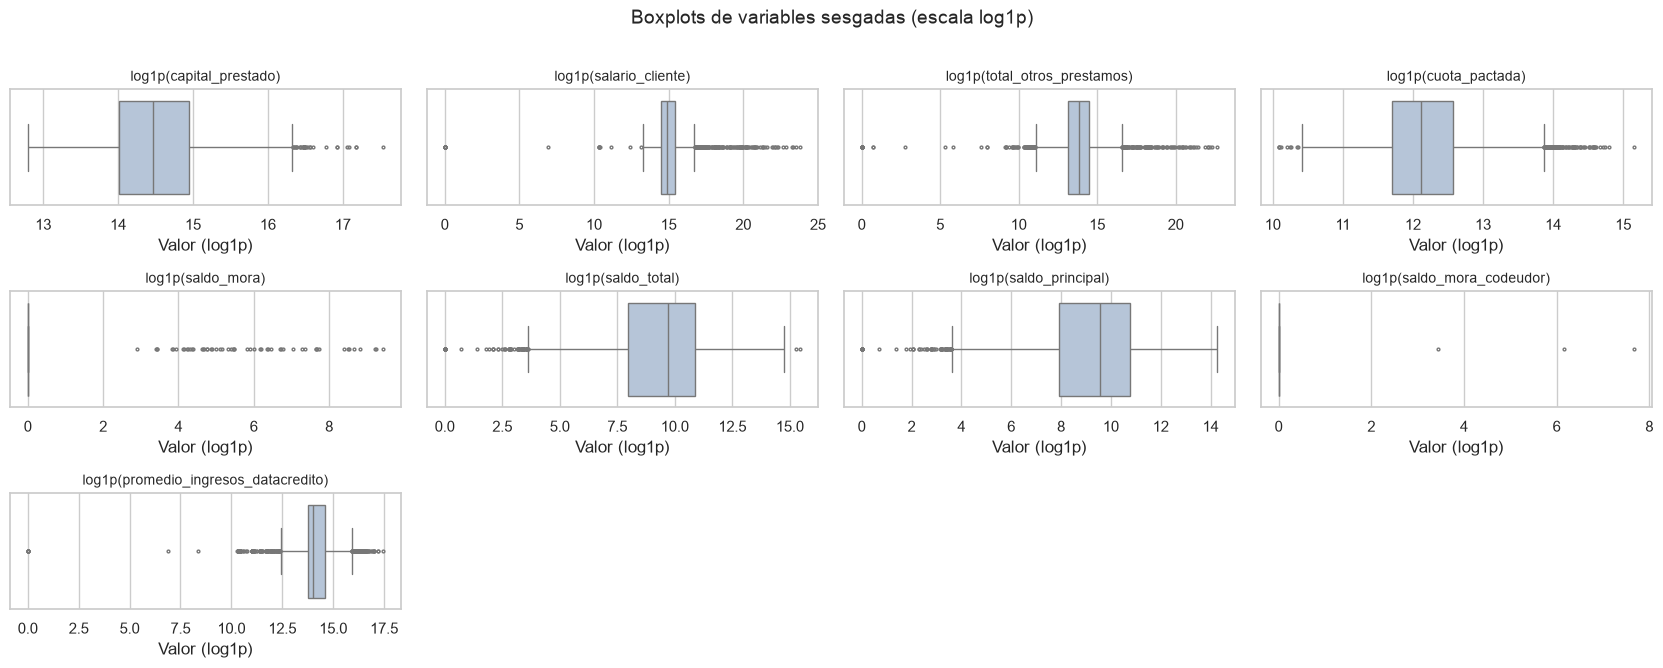

In [24]:
# Boxplots de las variables sesgadas en escala log1p
graficar_grilla(variables_sesgadas, lambda columna, eje: boxplot_simple(columna, eje, variables_sesgadas),
                alto_fila=2.2, titulo="Boxplots de variables sesgadas (escala log1p)")

Incluso en escala logarítmica persisten outliers, por ejemplo en `salario_cliente` y `total_otros_prestamos`.

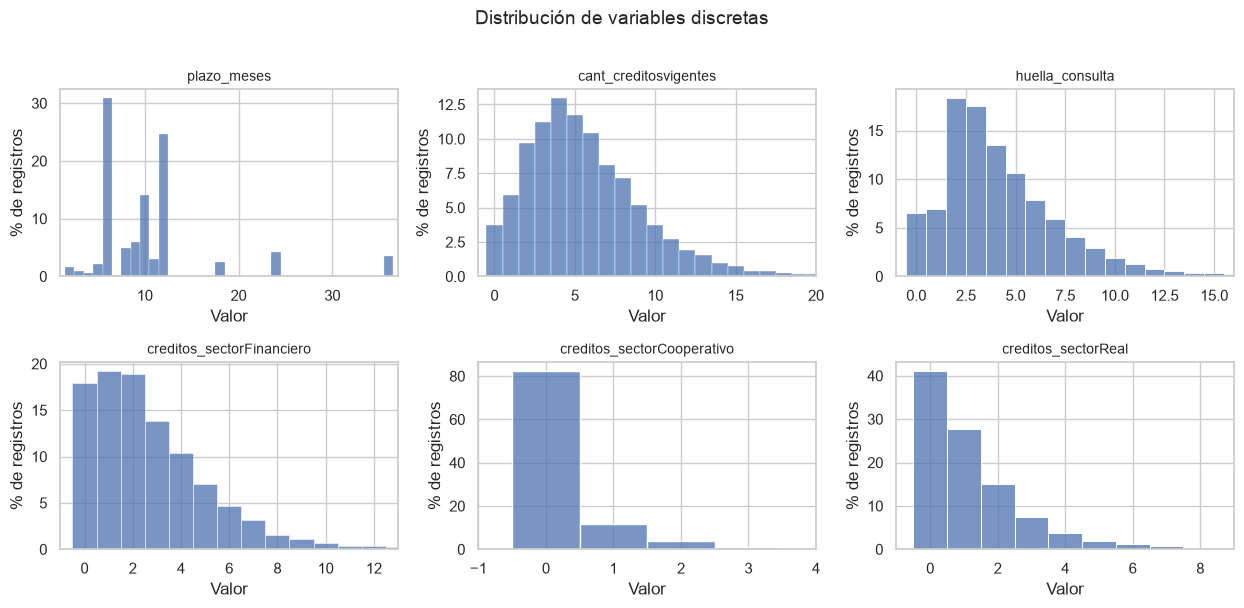

In [25]:
# Distribución de las variables discretas (recortadas al percentil 99 para legibilidad)
def barras_discretas(columna, eje):
    sns.histplot(df_eda[columna], discrete=True, stat="percent", ax=eje)
    eje.set_xlim(df_eda[columna].min() - 1, df_eda[columna].quantile(0.99) + 1)
    eje.set_title(columna, fontsize=10)
    eje.set_xlabel("Valor")
    eje.set_ylabel("% de registros")


graficar_grilla(variables_discretas, barras_discretas, n_columnas=3, titulo="Distribución de variables discretas")

Porcentaje de registros por valor en las variables de conteo y plazo. El eje X se recorta al percentil 99 para que los valores extremos no aplasten el gráfico.

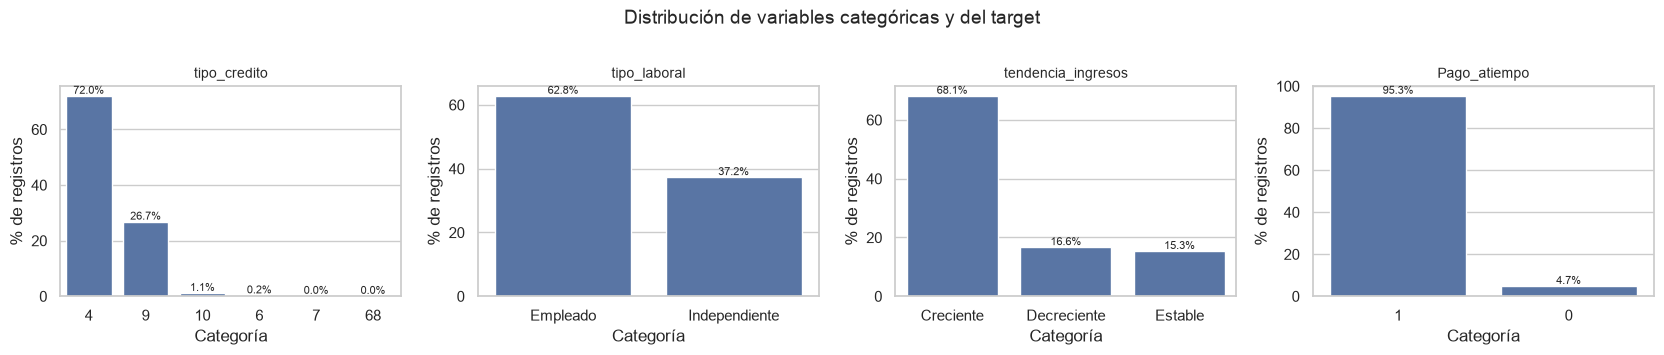

In [26]:
# Frecuencia de las variables categóricas y de la variable objetivo
def barras_categoricas(columna, eje):
    porcentajes = etiquetar_nulos(df_eda[columna]).value_counts(normalize=True) * 100
    sns.barplot(x=porcentajes.index, y=porcentajes.values, order=porcentajes.index, ax=eje)
    eje.bar_label(eje.containers[0], fmt="%.1f%%", fontsize=8)
    eje.set_title(columna, fontsize=10) 
    eje.set_xlabel("Categoría")
    eje.set_ylabel("% de registros")


graficar_grilla(variables_categoricas + [target], barras_categoricas, n_columnas=4, alto_fila=3.5,
                titulo="Distribución de variables categóricas y del target")

#### Conclusiones del análisis univariable

- **Variables monetarias muy sesgadas a la derecha:** las 9 variables monetarias tienen asimetría mayor a 2 y ningún valor negativo. Los casos más extremos son `salario_cliente`, `total_otros_prestamos`, `saldo_mora`, `saldo_mora_codeudor` y `saldo_total`, con asimetrías de decenas. La escala `log1p` mejora mucho su lectura, pero persisten outliers, así que conviene combinar la transformación `log` con recortes por percentil.
- **Variables casi constantes:** `saldo_mora` y `saldo_mora_codeudor` son 0 en más del 99% de los registros, así que su aporte individual es muy bajo.
- **`puntaje` concentrado en un solo valor:** la mayoría de los registros tiene exactamente 95.23, con una cola larga hacia valores bajos que incluye incluso valores negativos. `puntaje_datacredito` también tiene valores negativos (mínimo de -7).
- **`creditos_sectorCooperativo`** es 0 en el 82% de los casos, y `creditos_sectorReal` en el 41%.
- **`tipo_credito` dominado por dos códigos:** los códigos 4 (72.0%) y 9 (26.7%) suman casi el 99%. El código 10 tiene 116 registros (1.1%), el 6 tiene 21, y los códigos 7 y 68 apenas suman 3 registros.
- **`plazo_meses`** se concentra en plazos de 6, 12 y 10 meses (31%, 25% y 14% de los registros, respectivamente).
- **`edad_cliente`** tiene un grupo separado de 121 a 123 años, que corresponde a clientes sin historial en Datacrédito (ver Paso 1).
- **Target:** 95.25% pagó a tiempo y 4.75% no, lo que confirma el desbalance.

### 2.2 Análisis bivariable

Se evalúa qué variables diferencian a los clientes que pagan a tiempo (1) de los que no (0) y, al final, cómo se relacionan entre sí algunos pares de variables clave.

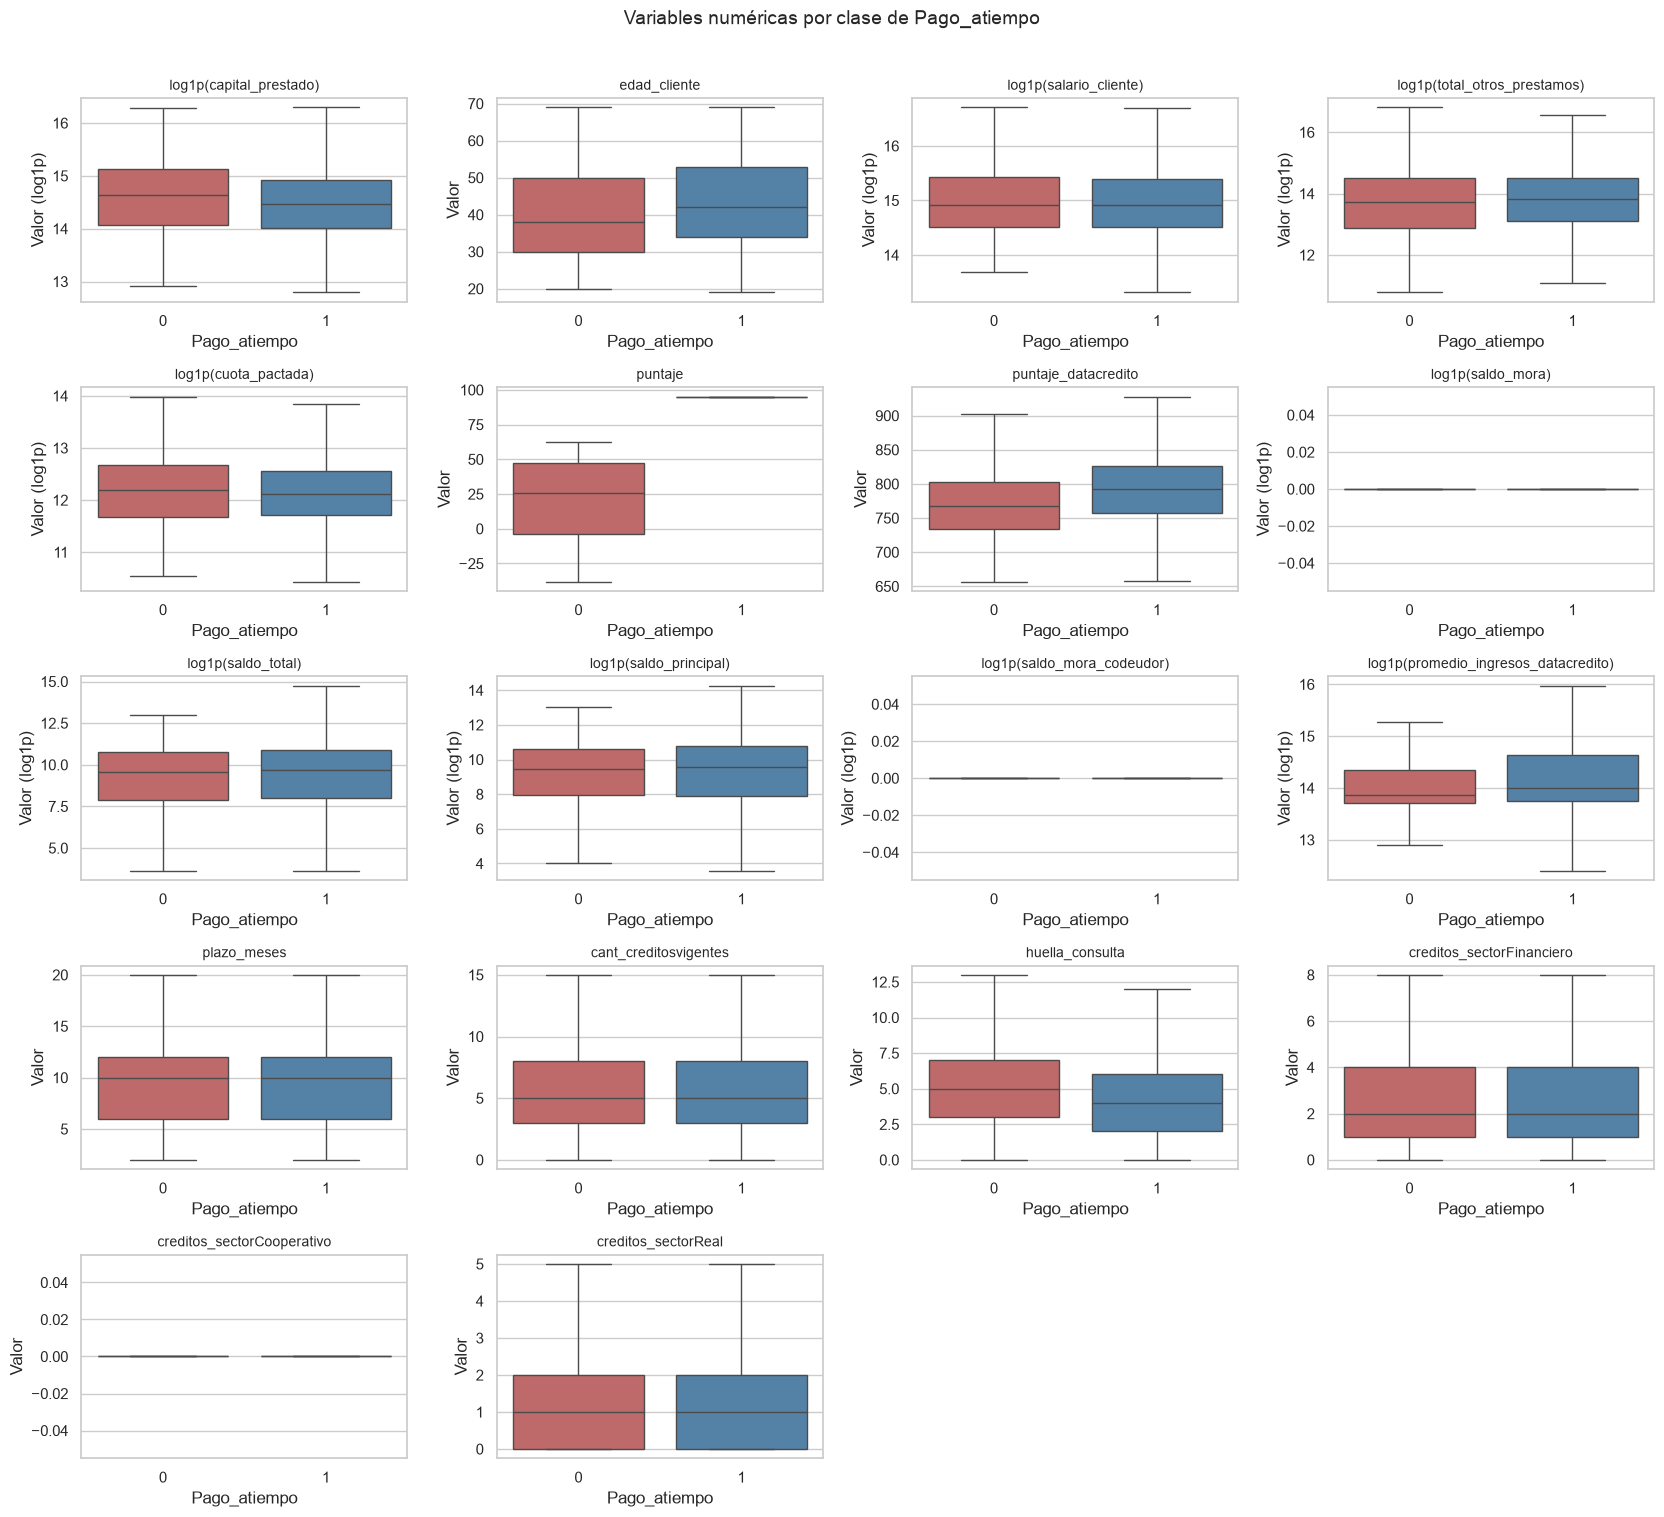

In [27]:
# Boxplots de variables numéricas por clase del target (sin outliers para ver mejor las cajas)
def boxplot_por_clase(columna, eje):
    serie, etiqueta = serie_para_grafico(columna, variables_sesgadas)
    sns.boxplot(x=df_eda.loc[serie.index, target], y=serie, hue=df_eda.loc[serie.index, target],
                palette={0: "indianred", 1: "steelblue"}, legend=False, showfliers=False, ax=eje)
    eje.set_title(etiqueta, fontsize=10)
    eje.set_xlabel(target)
    eje.set_ylabel("Valor (log1p)" if columna in variables_sesgadas else "Valor")


graficar_grilla(variables_numericas, boxplot_por_clase, titulo="Variables numéricas por clase de Pago_atiempo")

Se compara la distribución de cada variable numérica entre quienes no pagaron a tiempo (0, rojo) y quienes sí (1, azul). Mientras menos se solapen las cajas, más poder discriminante tiene la variable.

In [28]:
# Prueba de Mann-Whitney U y AUC univariado por variable numérica
filas = []
for columna in variables_numericas:
    pago_a_tiempo = df_eda.loc[df_eda[target] == 1, columna].dropna()
    con_impago = df_eda.loc[df_eda[target] == 0, columna].dropna()
    estadistico_u, p_valor = stats.mannwhitneyu(pago_a_tiempo, con_impago)
    auc = estadistico_u / (len(pago_a_tiempo) * len(con_impago))
    filas.append({
        "variable": columna,
        "mediana_pago_atiempo": pago_a_tiempo.median(),
        "mediana_impago": con_impago.median(),
        "auc_univariado": auc,
        "separacion": abs(auc - 0.5),
        "p_valor": p_valor,
    })

pruebas_numericas = pd.DataFrame(filas).set_index("variable").sort_values("separacion", ascending=False)
pruebas_numericas.style.format({
    "mediana_pago_atiempo": "{:,.2f}", "mediana_impago": "{:,.2f}",
    "auc_univariado": "{:.3f}", "separacion": "{:.3f}", "p_valor": "{:.2e}",
})

,mediana_pago_atiempo,mediana_impago,auc_univariado,separacion,p_valor
variable,,,,,
puntaje,95.23,25.42,1.000,0.500,0.00e+00
puntaje_datacredito,792.00,768.00,0.623,0.123,5.55e-21
huella_consulta,4.00,5.00,0.402,0.098,3.91e-14
promedio_ingresos_datacredito,"1,211,296.00","1,052,529.00",0.573,0.073,5.27e-06
edad_cliente,42.00,38.00,0.569,0.069,1.26e-07
capital_prestado,"1,908,446.40","2,268,000.00",0.443,0.057,1.33e-05
creditos_sectorFinanciero,2.00,2.00,0.541,0.041,1.68e-03
total_otros_prestamos,"1,000,000.00","900,000.00",0.535,0.035,6.76e-03
creditos_sectorReal,1.00,1.00,0.476,0.024,5.88e-02


La **prueba de Mann-Whitney U** es no paramétrica, adecuada para variables sesgadas. Contrasta si una clase tiende a tener valores mayores que la otra.

A partir del estadístico U se calcula el **AUC univariado**: la probabilidad de que un cliente que pagó a tiempo tenga un valor mayor que uno con impago. Un AUC de 0.5 indica que la variable no separa las clases, y 0 o 1 indican separación perfecta. La columna `separacion` ($|AUC - 0.5|$) ordena las variables por poder discriminante.

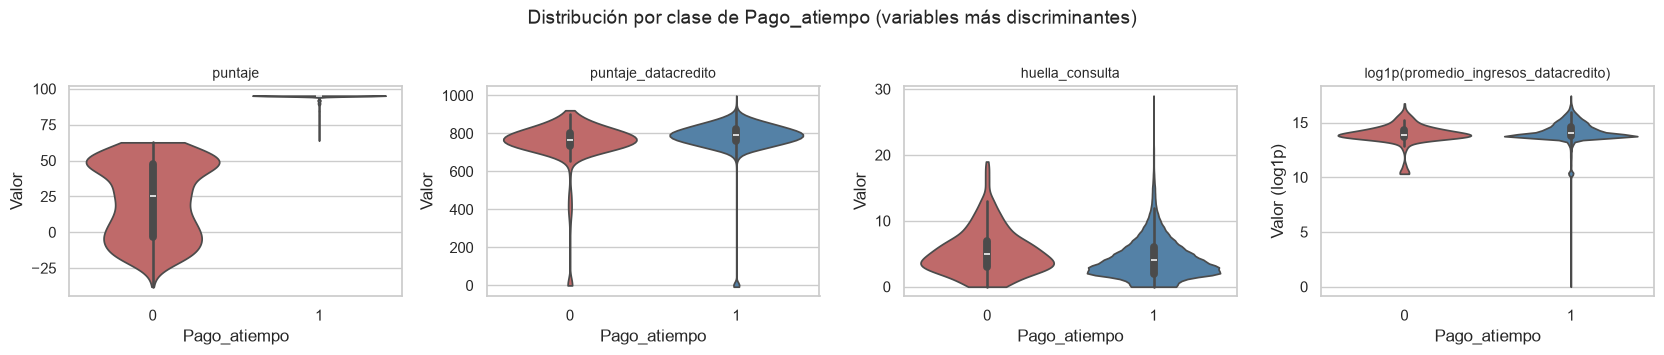

In [29]:
# Violinplots de las variables con mayor separación entre clases
variables_destacadas = pruebas_numericas.head(4).index.tolist()


def violin_por_clase(columna, eje):
    serie, etiqueta = serie_para_grafico(columna, variables_sesgadas)
    clase = df_eda.loc[serie.index, target]
    sns.violinplot(x=clase, y=serie, hue=clase, palette={0: "indianred", 1: "steelblue"},
                   legend=False, cut=0, ax=eje)
    eje.set_title(etiqueta, fontsize=10)
    eje.set_ylabel("Valor (log1p)" if columna in variables_sesgadas else "Valor")


graficar_grilla(variables_destacadas, violin_por_clase, n_columnas=4, alto_fila=3.5,
                titulo="Distribución por clase de Pago_atiempo (variables más discriminantes)")

Los violinplots muestran la forma completa de la distribución por clase en las 4 variables con mayor separación según la tabla anterior (`puntaje`, `puntaje_datacredito`, `huella_consulta` y `promedio_ingresos_datacredito`, esta última en escala `log1p`). Se ve claramente que `puntaje` no se solapa entre clases, mientras que en las otras tres las distribuciones se solapan casi por completo y solo se desplazan ligeramente.

In [30]:
# Verificación de posible fuga de información (data leakage) en `puntaje`
display(df_eda.groupby(target)["puntaje"].describe())

max_puntaje_impago = df_eda.loc[df_eda[target] == 0, "puntaje"].max()
min_puntaje_pago = df_eda.loc[df_eda[target] == 1, "puntaje"].min()
print(f"Máximo puntaje con impago:          {max_puntaje_impago:.2f}")
print(f"Mínimo puntaje con pago a tiempo:   {min_puntaje_pago:.2f}")
print(f"¿Separación perfecta?: {max_puntaje_impago < min_puntaje_pago}")

,count,mean,std,min,25%,50%,75%,max
Pago_atiempo,,,,,,,,
0,511.00,23.09,26.07,-38.01,-3.59,25.42,47.61,62.67
1,"10,252.00",94.56,2.87,63.81,95.23,95.23,95.23,95.23


Máximo puntaje con impago:          62.67
Mínimo puntaje con pago a tiempo:   63.81
¿Separación perfecta?: True


**Alerta de *data leakage*:** `puntaje` separa las clases de forma perfecta. Todos los clientes con impago tienen un puntaje menor que cualquier cliente que pagó a tiempo.

Un comportamiento así casi nunca ocurre con una variable disponible al momento de otorgar el crédito. Lo más probable es que `puntaje` se calcule **después** de observar el pago, o a partir de él. Si se usa en el modelo, este obtendrá métricas perfectas en validación pero fallará en producción con usuarios nuevos.


In [31]:
# Tasa de impago según si el cliente tiene saldo en mora
tiene_mora = etiquetar_nulos(df_eda["saldo_mora"].gt(0).where(df_eda["saldo_mora"].notna()))
df_eda.groupby(tiene_mora)["impago"].agg(registros="size", pct_impago=lambda s: s.mean() * 100)

,registros,pct_impago
saldo_mora,,
False,10552,4.55
True,55,36.36


`saldo_mora` tiene mediana 0 en ambas clases, pero su p-valor en Mann-Whitney es muy bajo. La razón es que los pocos clientes con saldo en mora mayor a 0 concentran una tasa de impago muy superior a la global. Por eso, un indicador binario `tiene_mora` puede aportar más que el monto.

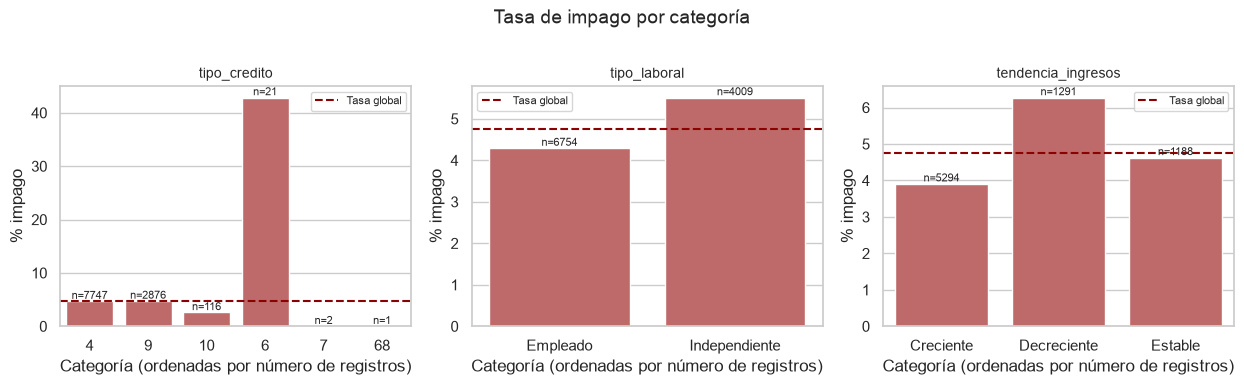

In [32]:
# Tasa de impago por categoría (la línea roja marca la tasa global)
def tasa_impago_por_categoria(columna, eje):
    categoria = etiquetar_nulos(df_eda[columna])
    resumen = df_eda.groupby(categoria)["impago"].agg(["mean", "size"]).sort_values("size", ascending=False)
    sns.barplot(x=resumen.index, y=resumen["mean"] * 100, order=resumen.index, color="indianred", ax=eje)
    eje.axhline(tasa_impago_global * 100, ls="--", color="darkred", label="Tasa global")
    eje.bar_label(eje.containers[0], labels=[f"n={n}" for n in resumen["size"]], fontsize=8)
    eje.set_title(columna, fontsize=10)
    eje.set_xlabel("Categoría (ordenadas por número de registros)")
    eje.set_ylabel("% impago")
    eje.legend(fontsize=8)


graficar_grilla(variables_categoricas, tasa_impago_por_categoria, n_columnas=3, alto_fila=3.8,
                titulo="Tasa de impago por categoría")

Se compara la tasa de impago de cada categoría con la tasa global (4.75%). Sobre cada barra se indica el tamaño de la muestra (`n`): en categorías con pocos registros, la tasa es poco confiable.

In [33]:
# Prueba chi-cuadrado de independencia y V de Cramer para variables categóricas
filas = []
for columna in variables_categoricas:
    tabla = pd.crosstab(etiquetar_nulos(df_eda[columna]), df_eda[target])
    chi2, p_valor, grados_libertad, frecuencias_esperadas = stats.chi2_contingency(tabla)
    v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    filas.append({
        "variable": columna,
        "chi2": chi2,
        "p_valor": p_valor,
        "v_cramer": v_cramer,
        "pct_celdas_esperado_menor_5": (frecuencias_esperadas < 5).mean() * 100,
    })

pruebas_categoricas = pd.DataFrame(filas).set_index("variable").sort_values("v_cramer", ascending=False)
pruebas_categoricas.style.format({"chi2": "{:.2f}", "p_valor": "{:.2e}", "v_cramer": "{:.3f}",
                                  "pct_celdas_esperado_menor_5": "{:.1f}"})

,chi2,p_valor,v_cramer,pct_celdas_esperado_menor_5
variable,,,,
tipo_credito,68.86,1.77e-13,0.080,41.7
tendencia_ingresos,13.91,9.54e-04,0.042,0.0
tipo_laboral,8.00,4.69e-03,0.027,0.0


La **prueba chi-cuadrado** contrasta si la categoría y el target son independientes, y la **V de Cramer** mide la fuerza de la asociación en una escala de 0 a 1.

La columna `pct_celdas_esperado_menor_5` advierte cuándo la prueba es poco fiable: si muchas celdas tienen una frecuencia esperada menor a 5, como ocurre con los códigos raros de `tipo_credito`, el p-valor debe tomarse con cautela.

In [34]:
# ¿Los valores faltantes aportan información sobre el impago?
columnas_con_nulos = [c for c in df_eda.columns if df_eda[c].isna().any()]

impago_por_nulos = pd.DataFrame({
    "n_nulos": df_eda[columnas_con_nulos].isna().sum(),
    "pct_impago_con_dato": [df_eda.loc[df_eda[c].notna(), "impago"].mean() * 100 for c in columnas_con_nulos],
    "pct_impago_sin_dato": [df_eda.loc[df_eda[c].isna(), "impago"].mean() * 100 for c in columnas_con_nulos],
}, index=columnas_con_nulos)
impago_por_nulos["p_valor_chi2"] = [
    stats.chi2_contingency(pd.crosstab(df_eda[c].isna(), df_eda[target]))[1] for c in columnas_con_nulos
]

impago_por_nulos.sort_values("n_nulos", ascending=False).style.format(
    {"pct_impago_con_dato": "{:.2f}", "pct_impago_sin_dato": "{:.2f}", "p_valor_chi2": "{:.2f}"}
)

,n_nulos,pct_impago_con_dato,pct_impago_sin_dato,p_valor_chi2
tendencia_ingresos,2990,4.41,5.62,0.01
promedio_ingresos_datacredito,2930,4.38,5.73,0.00
saldo_mora_codeudor,590,4.63,6.78,0.02
saldo_principal,405,4.65,7.16,0.03
saldo_mora,156,4.71,7.05,0.24
saldo_total,156,4.71,7.05,0.24
puntaje_datacredito,6,4.74,16.67,0.68


Se compara la tasa de impago entre los registros con y sin dato en cada columna con faltantes. Si la diferencia es significativa, el faltante es **informativo**. En ese caso, en lugar de solo imputar, conviene crear una variable indicadora (`flag`) de dato faltante.

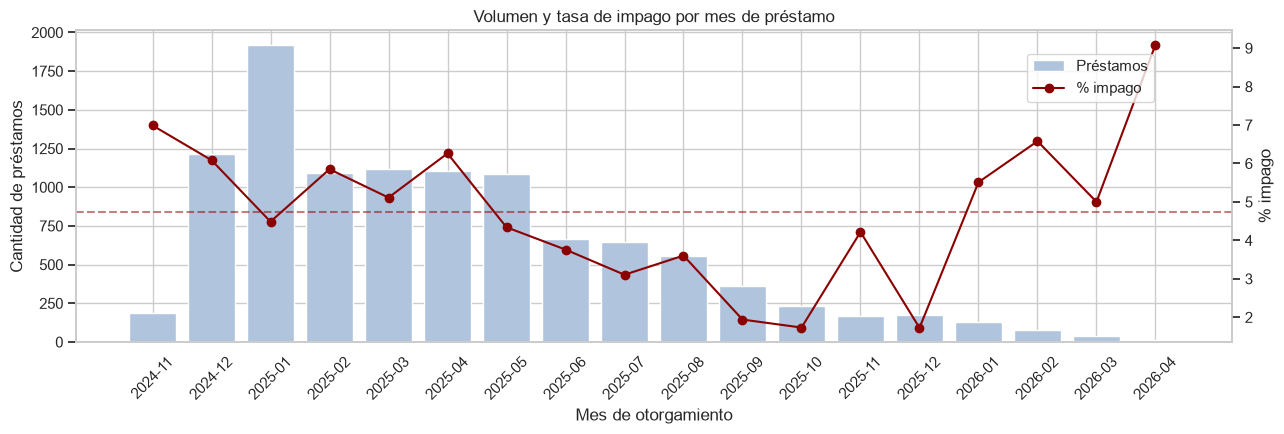

mes_prestamo,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
prestamos,186.00,"1,216.00","1,917.00","1,094.00","1,115.00","1,102.00","1,083.00",665.00,644.00,555.00,361.00,231.00,166.00,174.00,127.00,76.00,40.00,11.00
tasa_impago,6.99,6.09,4.49,5.85,5.11,6.26,4.34,3.76,3.11,3.60,1.94,1.73,4.22,1.72,5.51,6.58,5.00,9.09


In [35]:
# Volumen de préstamos y tasa de impago por mes de otorgamiento
por_mes = df_eda.groupby("mes_prestamo").agg(prestamos=("impago", "size"), tasa_impago=("impago", "mean"))
meses = por_mes.index.astype(str)

fig, eje_volumen = plt.subplots(figsize=(13, 4.5))
eje_volumen.bar(meses, por_mes["prestamos"], color="lightsteelblue", label="Préstamos")
eje_volumen.set_xlabel("Mes de otorgamiento")
eje_volumen.set_ylabel("Cantidad de préstamos")
eje_volumen.tick_params(axis="x", rotation=45)

eje_tasa = eje_volumen.twinx()
eje_tasa.plot(meses, por_mes["tasa_impago"] * 100, color="darkred", marker="o", label="% impago")
eje_tasa.axhline(tasa_impago_global * 100, ls="--", color="darkred", alpha=0.5)
eje_tasa.set_ylabel("% impago")
eje_tasa.grid(False)

fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
eje_volumen.set_title("Volumen y tasa de impago por mes de préstamo")
plt.tight_layout()
plt.show()

por_mes.assign(tasa_impago=por_mes["tasa_impago"] * 100).T

Las barras muestran el volumen mensual de préstamos y la línea, la tasa de impago de cada mes. La línea punteada es la tasa global. Con esto se evalúa si la tasa cambia con el tiempo (por estacionalidad o por falta de madurez de los créditos), lo que define si conviene validar el modelo con un split temporal.

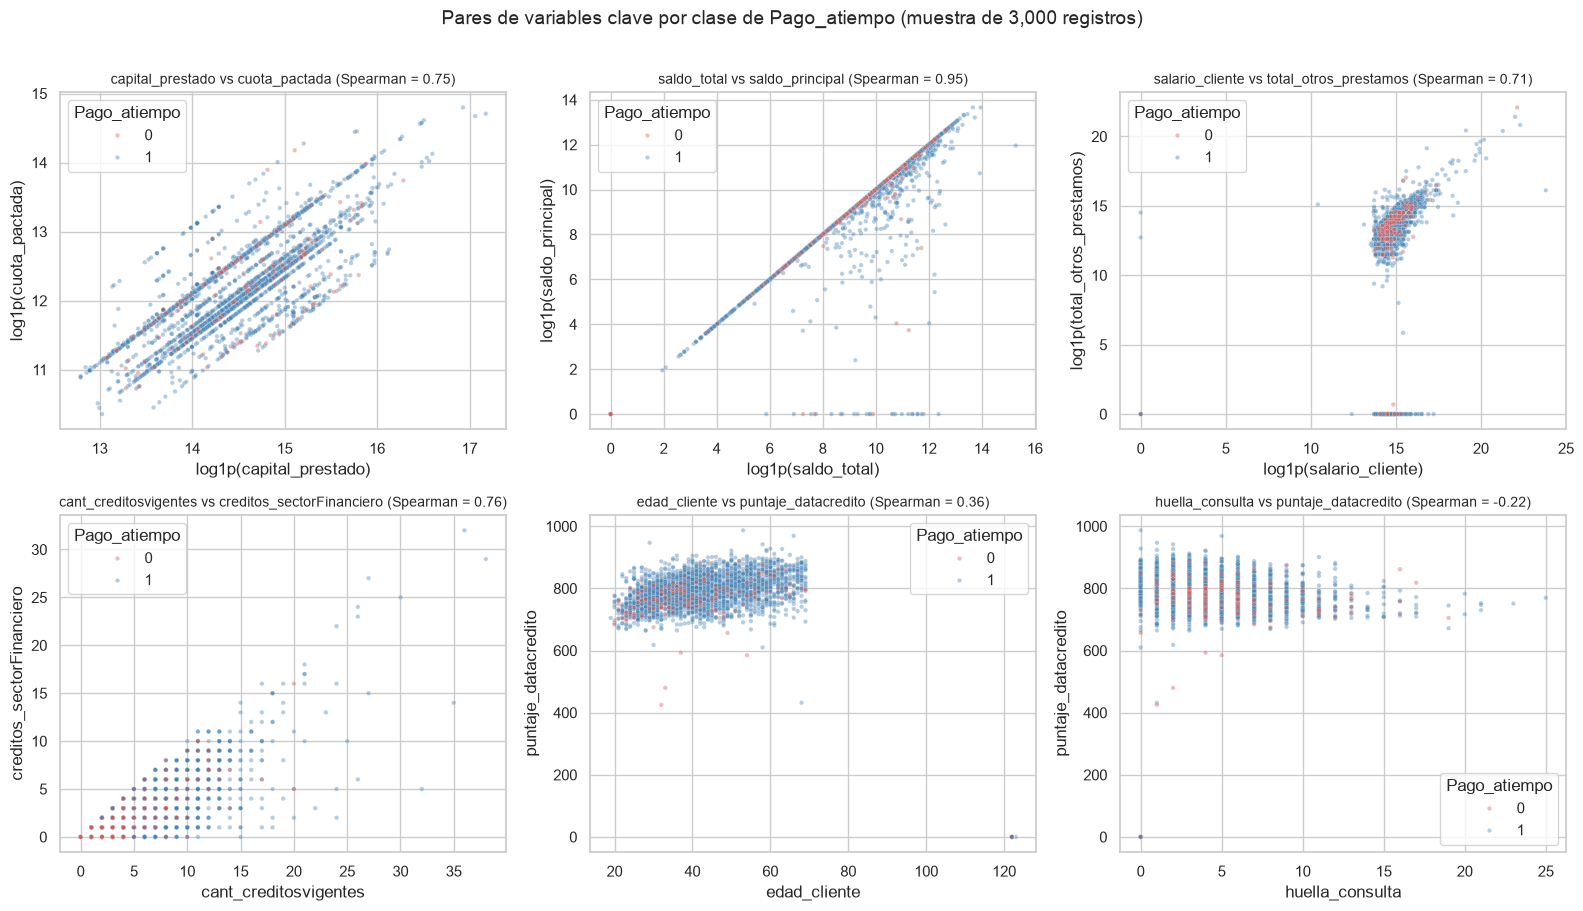

In [36]:
# Relación entre pares de variables clave (muestra aleatoria; montos en escala log1p)
pares_clave = [
    ("capital_prestado", "cuota_pactada"),
    ("saldo_total", "saldo_principal"),
    ("salario_cliente", "total_otros_prestamos"),
    ("cant_creditosvigentes", "creditos_sectorFinanciero"),
    ("edad_cliente", "puntaje_datacredito"),
    ("huella_consulta", "puntaje_datacredito"),
]
muestra_pares = df_eda.sample(n=3000, random_state=SEMILLA)

fig, ejes = plt.subplots(2, 3, figsize=(16, 9))
for eje, (variable_x, variable_y) in zip(ejes.flatten(), pares_clave):
    x, etiqueta_x = serie_para_grafico(variable_x, variables_sesgadas)
    y, etiqueta_y = serie_para_grafico(variable_y, variables_sesgadas)
    datos = pd.concat([x.rename("x"), y.rename("y"), df_eda[target]], axis=1, join="inner")
    datos = datos.loc[datos.index.intersection(muestra_pares.index)].sort_values(target, ascending=False)
    sns.scatterplot(data=datos, x="x", y="y", hue=target, palette={0: "indianred", 1: "steelblue"},
                    alpha=0.4, s=10, ax=eje)
    rho = df_eda[[variable_x, variable_y]].corr(method="spearman").iloc[0, 1]
    eje.set_title(f"{variable_x} vs {variable_y} (Spearman = {rho:.2f})", fontsize=10)
    eje.set_xlabel(etiqueta_x)
    eje.set_ylabel(etiqueta_y)
fig.suptitle("Pares de variables clave por clase de Pago_atiempo (muestra de 3,000 registros)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [37]:
# Verificaciones numéricas de lo observado en los pares de variables
registros_sector_mayor_total = (df_eda["creditos_sectorFinanciero"] > df_eda["cant_creditosvigentes"]).sum()
principal_cero_total_positivo = ((df_eda["saldo_principal"] == 0) & (df_eda["saldo_total"] > 0)).sum()

puntaje_bajo = df_eda["puntaje_datacredito"].between(0, 600, inclusive="neither")
impago_puntaje_bajo = df_eda.loc[puntaje_bajo, "impago"]

print(f"Registros con creditos_sectorFinanciero > cant_creditosvigentes: {registros_sector_mayor_total}")
print(f"Registros con saldo_principal = 0 y saldo_total > 0: {principal_cero_total_positivo}")
print(f"Registros con 0 < puntaje_datacredito < 600: {puntaje_bajo.sum()} "
      f"(con impago: {impago_puntaje_bajo.sum()}, {impago_puntaje_bajo.mean():.0%})")

Registros con creditos_sectorFinanciero > cant_creditosvigentes: 0
Registros con saldo_principal = 0 y saldo_total > 0: 93
Registros con 0 < puntaje_datacredito < 600: 26 (con impago: 16, 62%)


Diagramas de dispersión de pares de variables relacionadas entre sí, coloreados por clase, sobre una muestra aleatoria de 3,000 registros. En el título de cada panel se indica la correlación de Spearman calculada con todos los datos, y las cifras provienen de la verificación anterior, también con todos los datos.

- **`capital_prestado` y `cuota_pactada`:** forman bandas diagonales paralelas, una por cada plazo. La cuota queda determinada casi por completo por el capital y el plazo.
- **`saldo_total` y `saldo_principal`:** la mayoría de los puntos está sobre la diagonal (ambos saldos son iguales) y el resto queda por debajo, con un grupo de 93 registros con `saldo_principal` en 0 y saldo total positivo.
- **`salario_cliente` y `total_otros_prestamos`:** relación positiva concentrada en un núcleo denso, con un grupo de clientes sin otros préstamos (valor 0).
- **`cant_creditosvigentes` y `creditos_sectorFinanciero`:** `creditos_sectorFinanciero` nunca supera a `cant_creditosvigentes` (0 registros): los créditos del sector financiero son una parte del total de créditos vigentes.
- **`edad_cliente` y `puntaje_datacredito`:** correlación positiva moderada (los clientes mayores tienen puntajes algo más altos) y el grupo aislado de clientes sin historial (alrededor de 122 años y puntaje 0).
- **`huella_consulta` y `puntaje_datacredito`:** correlación negativa débil. Los puntajes positivos por debajo de 600 son pocos (26 registros), pero 16 de ellos (62%) corresponden a clientes con impago, frente al 4.75% global.

En ningún par las clases forman grupos separados: la señal está repartida y es débil en cada par por separado.

#### Conclusiones del análisis bivariable

Ranking de asociación con el target:

1. **`puntaje`:** separación perfecta (AUC = 1.0). Es un caso de *data leakage* probable y debe excluirse del modelo.
2. **`puntaje_datacredito`:** la variable legítima más discriminante. Los clientes con impago tienen puntajes más bajos (mediana de 768 frente a 792).
3. **`huella_consulta`:** más consultas en centrales de riesgo se asocian con mayor impago.
4. **`promedio_ingresos_datacredito` y `edad_cliente`:** los clientes con impago tienen ingresos reportados menores y son más jóvenes.
5. **`capital_prestado`:** los préstamos con impago tienen montos algo mayores.
6. **`tipo_credito`:** el código 6 tiene una tasa de impago muy superior a la global, aunque con pocos casos.
7. **`tendencia_ingresos` y `tipo_laboral`:** asociación significativa pero débil. Los ingresos "Decreciente" y los trabajadores "Independiente" tienen más impago.

Otras observaciones:

- **Variables sin diferencias significativas entre clases** (p-valor > 0.05 en Mann-Whitney): `salario_cliente`, `saldo_principal`, `saldo_mora_codeudor`, `cuota_pactada`, `saldo_total`, `plazo_meses`, `cant_creditosvigentes` y `creditos_sectorReal`.
- **Mora actual:** los clientes con `saldo_mora` mayor a 0 son pocos (55), pero tienen una tasa de impago de alrededor de 36%.
- **Faltantes informativos:** cuando falta información de Datacrédito (`promedio_ingresos_datacredito` o `tendencia_ingresos`), el impago sube de alrededor de 4.4% a 5.7%. Algo parecido ocurre con `saldo_principal` y `saldo_mora_codeudor`. Conviene crear *flags* de dato faltante.
- **Tiempo:**
  - La tasa de impago mensual oscila entre 1.7% (octubre y diciembre de 2025) y 9.1% (abril de 2026, con solo 11 préstamos).
  - Entre noviembre de 2024 y mayo de 2025, los meses de mayor volumen, se mantiene entre 4.3% y 7.0%.
  - De junio a diciembre de 2025 baja a entre 1.7% y 3.8%, salvo noviembre (4.2%).
  - Vuelve a subir en 2026 (entre 5.0% y 9.1%), aunque con muy pocos préstamos por mes (entre 11 y 127).
  - El comportamiento no es estable en el tiempo, lo que justifica una validación temporal.
- **Pares de variables clave:** los pares más correlacionados (`saldo_total` y `saldo_principal`, `capital_prestado` y `cuota_pactada`) muestran relaciones casi lineales en escala `log1p`, y en ningún par las clases forman grupos separados.

### 2.3 Análisis multivariable

Se estudian las relaciones entre varias variables a la vez: redundancia (multicolinealidad), separabilidad conjunta de las clases e interacciones.

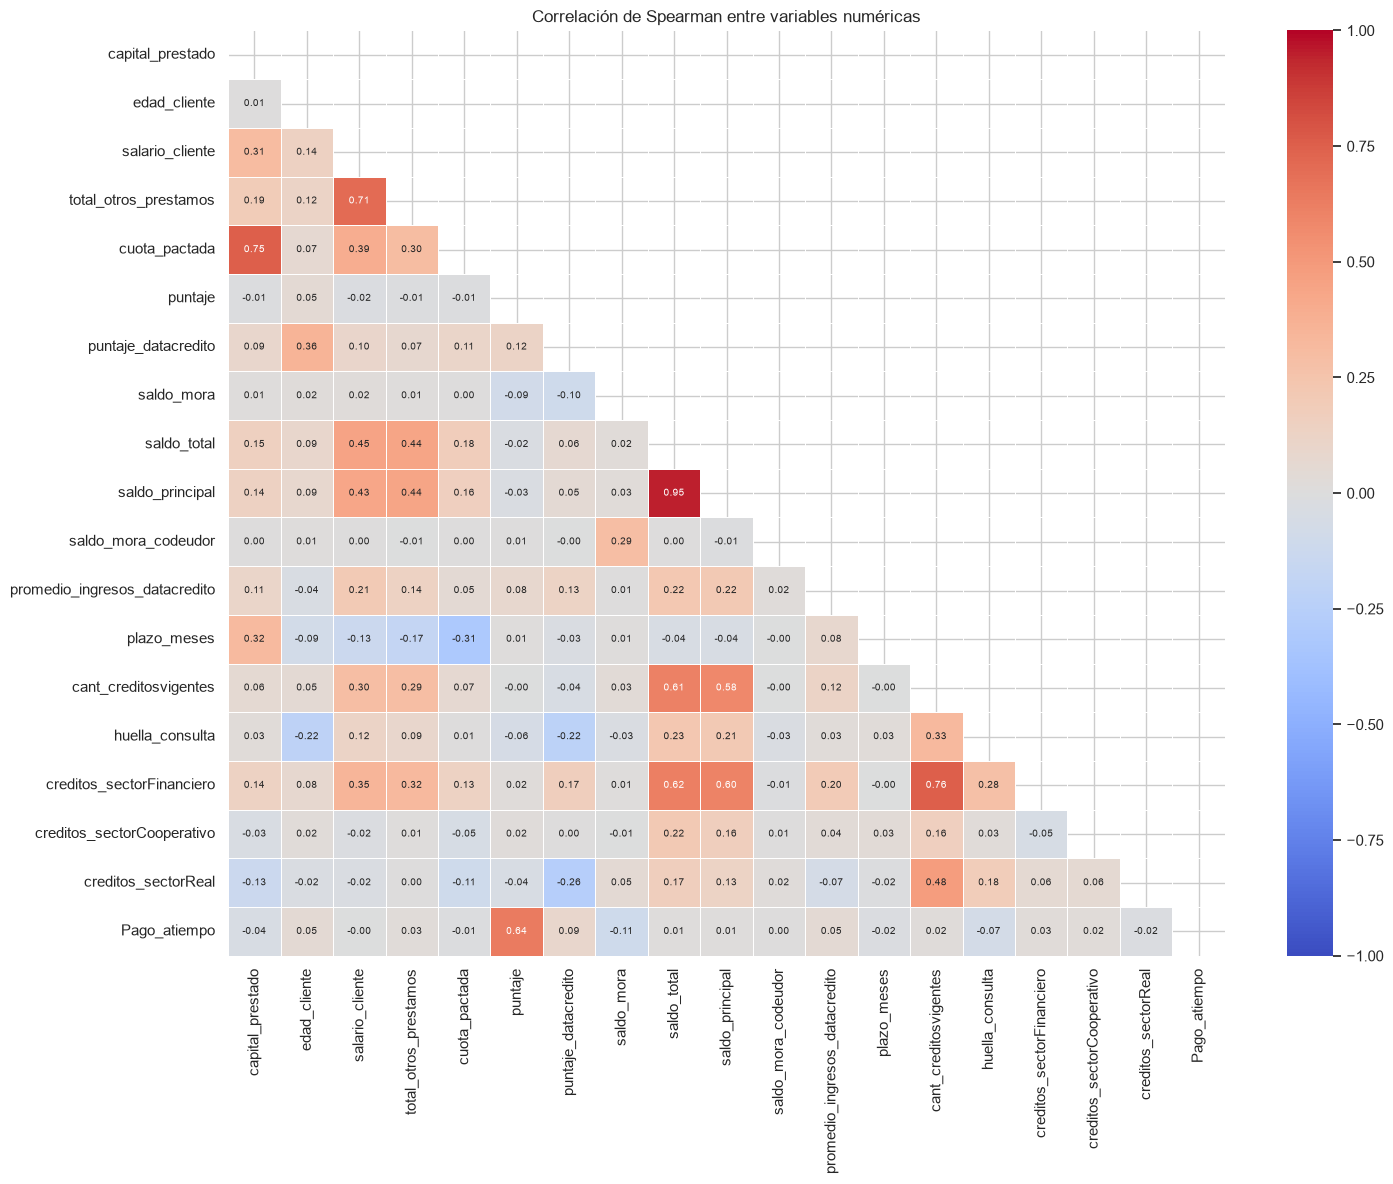

In [38]:
# Matriz de correlación de Spearman (robusta a sesgo y outliers)
correlaciones = df_eda[variables_numericas + [target]].corr(method="spearman")
mascara = np.triu(np.ones_like(correlaciones, dtype=bool))

plt.figure(figsize=(15, 12))
sns.heatmap(correlaciones, mask=mascara, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5)
plt.title("Correlación de Spearman entre variables numéricas")
plt.tight_layout()
plt.show()

Se usa la correlación de **Spearman** (por rangos) en lugar de la de Pearson, porque las variables son muy sesgadas y tienen outliers. La última fila muestra la correlación de cada variable con `Pago_atiempo`.

In [39]:
# Pares de variables altamente correlacionadas (|rho| > 0.7)
pares_correlacion = (
    correlaciones.where(np.triu(np.ones(correlaciones.shape), k=1).astype(bool))
    .stack()
    .rename("spearman")
    .to_frame()
)
pares_correlacion[pares_correlacion["spearman"].abs() > 0.7].sort_values("spearman", key=abs, ascending=False)

,,spearman
saldo_total,saldo_principal,0.95
cant_creditosvigentes,creditos_sectorFinanciero,0.76
capital_prestado,cuota_pactada,0.75
salario_cliente,total_otros_prestamos,0.71


Lista de pares con correlación fuerte. En cada par, una de las variables es en buena parte redundante. Para modelos lineales conviene conservar solo una o combinarlas; los modelos de árboles, como XGBoost, toleran mejor la redundancia.

In [40]:
# Factor de inflación de la varianza (VIF): cuánto explica el resto de variables a cada una
variables_sin_fuga = [c for c in variables_numericas if c != "puntaje"]
datos_transformados = df_eda[variables_sin_fuga].copy()
datos_transformados[variables_sesgadas] = np.log1p(datos_transformados[variables_sesgadas])
datos_transformados = datos_transformados.fillna(datos_transformados.median())


def calcular_vif(datos, columna):
    otras = datos.drop(columns=columna)
    r2 = LinearRegression().fit(otras, datos[columna]).score(otras, datos[columna])
    return 1 / (1 - r2)


vif = pd.Series({c: calcular_vif(datos_transformados, c) for c in variables_sin_fuga}, name="VIF")
vif.sort_values(ascending=False).to_frame()

,VIF
capital_prestado,10.33
cant_creditosvigentes,10.09
cuota_pactada,9.66
creditos_sectorFinanciero,6.90
plazo_meses,4.51
saldo_total,3.47
creditos_sectorReal,3.32
saldo_principal,3.14
salario_cliente,1.40
creditos_sectorCooperativo,1.37


El **VIF** (*Variance Inflation Factor*) complementa a la correlación por pares: mide cuánto se puede explicar cada variable con todas las demás a la vez ($VIF = 1 / (1 - R^2)$). Se calcula sobre las variables numéricas sin `puntaje`, con las monetarias en escala `log1p` y los faltantes imputados con la mediana. Como regla práctica, un VIF mayor a 5 indica multicolinealidad moderada y uno mayor a 10, severa.

- `capital_prestado` (≈10.3) y `cuota_pactada` (≈9.7) son las más colineales: la cuota se deriva del capital y del plazo, por eso `plazo_meses` también tiene un VIF moderado (≈4.5).
- `cant_creditosvigentes` (≈10.1) queda muy explicada por los créditos por sector, en especial por `creditos_sectorFinanciero` (≈6.9).
- `saldo_total` (≈3.5), `saldo_principal` (≈3.1) y `creditos_sectorReal` (≈3.3) tienen un VIF por debajo de 5, es decir, una colinealidad baja a moderada. El resto de variables tiene un VIF menor a 1.5.
- En los saldos, el VIF es más bajo de lo que haría esperar su correlación de Spearman de 0.95. La razón es que el VIF mide relaciones **lineales** sobre los valores en escala `log1p`, mientras que Spearman solo mide el orden. Los 93 registros con `saldo_principal` en 0 y saldo total positivo, vistos en 2.2, rompen la relación lineal, pero casi no afectan el orden.

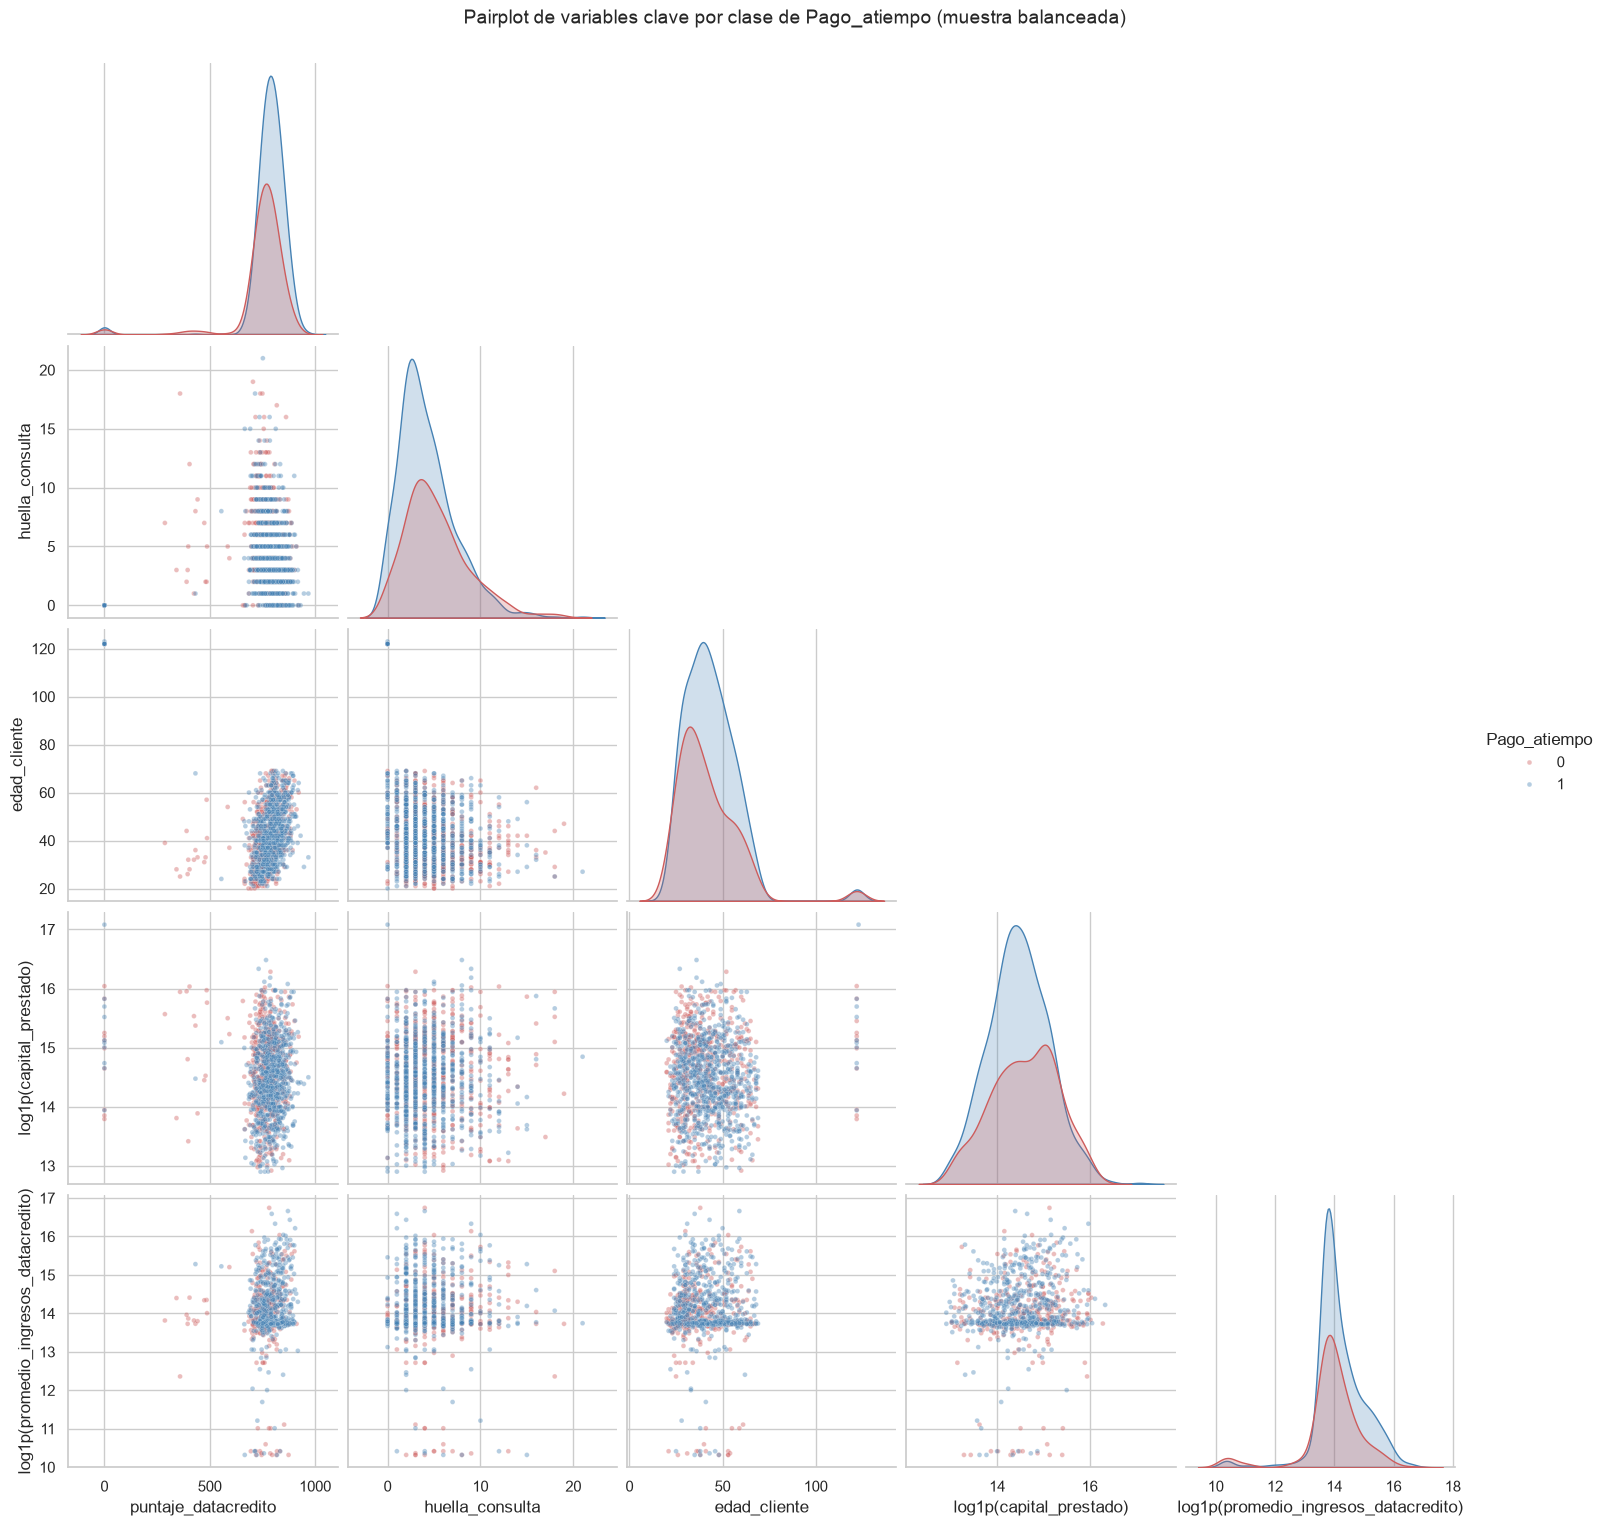

In [41]:
# Pairplot de variables clave sobre una muestra balanceada (sin `puntaje` por leakage)
variables_pairplot = ["puntaje_datacredito", "huella_consulta", "edad_cliente",
                      "capital_prestado", "promedio_ingresos_datacredito"]

muestra = pd.concat([
    grupo.sample(n=min(len(grupo), 800), random_state=SEMILLA) for _, grupo in df_eda.groupby(target)
])
muestra_pairplot = muestra[variables_pairplot + [target]].copy()
for columna in ["capital_prestado", "promedio_ingresos_datacredito"]:
    muestra_pairplot[f"log1p({columna})"] = np.log1p(muestra_pairplot.pop(columna))

grilla = sns.pairplot(muestra_pairplot, hue=target, corner=True, palette={0: "indianred", 1: "steelblue"},
                      plot_kws={"alpha": 0.4, "s": 12}, diag_kind="kde", height=3)
grilla.figure.suptitle("Pairplot de variables clave por clase de Pago_atiempo (muestra balanceada)", fontsize=14, y=1.02)
plt.show()

Diagramas de dispersión por pares de las variables legítimas más discriminantes, coloreados por clase. Se usa una muestra casi balanceada (los 511 casos con impago y 800 casos aleatorios de pago a tiempo) para que la clase minoritaria sea visible. Al combinar cinco variables con el color de la clase, es una vista multivariable. Los montos se grafican en escala `log1p`.

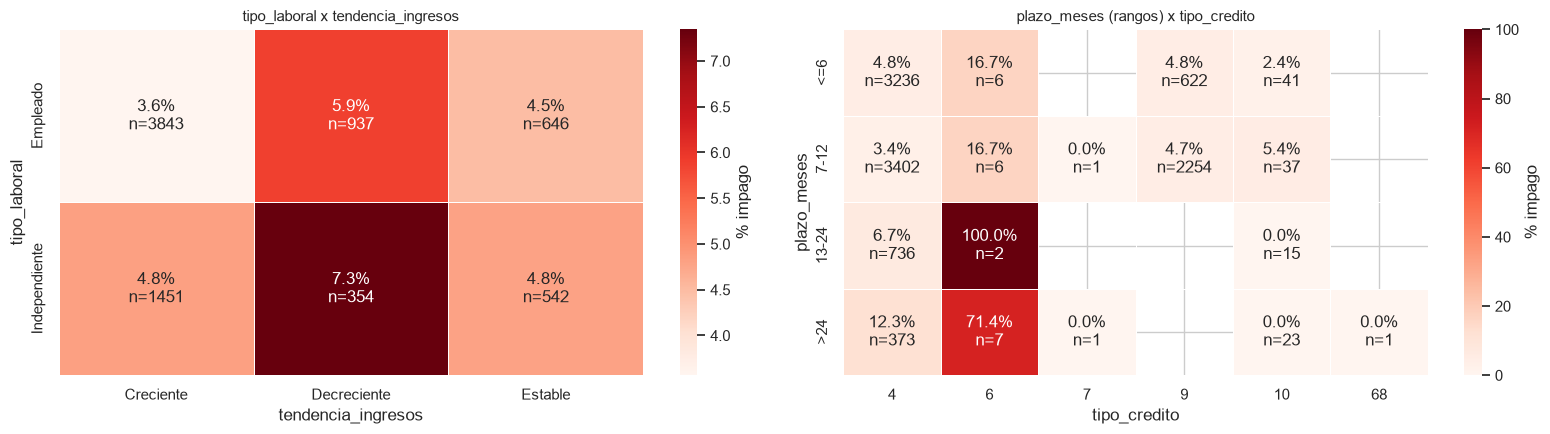

In [42]:
# Interacciones: tasa de impago por combinación de dos variables
def heatmap_tasa_impago(filas, columnas, eje, titulo):
    tasa = pd.crosstab(filas, columnas, values=df_eda["impago"], aggfunc="mean") * 100
    conteo = pd.crosstab(filas, columnas).reindex_like(tasa).fillna(0).astype(int)
    etiquetas = (tasa.round(1).astype(str) + "%\nn=" + conteo.astype(str)).where(conteo > 0, "")
    sns.heatmap(tasa, annot=etiquetas.values, fmt="", cmap="Reds", ax=eje,
                cbar_kws={"label": "% impago"}, linewidths=0.5)
    eje.set_title(titulo, fontsize=11)


rangos_plazo = pd.cut(df_eda["plazo_meses"], bins=[0, 6, 12, 24, 90], labels=["<=6", "7-12", "13-24", ">24"])

fig, ejes = plt.subplots(1, 2, figsize=(16, 4.5))
heatmap_tasa_impago(df_eda["tipo_laboral"], etiquetar_nulos(df_eda["tendencia_ingresos"]), ejes[0],
                    "tipo_laboral x tendencia_ingresos")
heatmap_tasa_impago(rangos_plazo, df_eda["tipo_credito"], ejes[1], "plazo_meses (rangos) x tipo_credito")
plt.tight_layout()
plt.show()

Cada celda muestra la tasa de impago de la combinación y el número de registros (`n`). Esto permite detectar **interacciones**: combinaciones cuyo riesgo es mayor que el que sugiere cada variable por separado. Por ejemplo, plazos largos dentro de un mismo tipo de crédito. Las celdas vacías indican combinaciones sin registros: el `tipo_credito` 9, por ejemplo, solo se otorga a plazos de hasta 12 meses.

#### Conclusiones del análisis multivariable

- **Redundancia:**
  - `saldo_total` y `saldo_principal` están casi duplicadas ($\rho \approx 0.95$).
  - `cant_creditosvigentes` y `creditos_sectorFinanciero` ($\rho \approx 0.76$) también lo están en buena parte.
  - `capital_prestado` y `cuota_pactada` ($\rho \approx 0.75$) y `salario_cliente` y `total_otros_prestamos` ($\rho \approx 0.71$) siguen la misma tendencia.
  - El VIF confirma multicolinealidad severa en `capital_prestado` (≈10.3) y `cant_creditosvigentes` (≈10.1). `cuota_pactada` (≈9.7) queda justo bajo el umbral de severa, y `creditos_sectorFinanciero` (≈6.9) tiene una multicolinealidad moderada.
  - Estos pares son candidatos a eliminar una de las dos variables o a construir ratios.
- **Separabilidad:**
  - Sin `puntaje`, las clases se solapan en todos los pares del pairplot de las variables más discriminantes: ninguna combinación de dos de ellas separa a quienes pagan de quienes no.
  - El problema es difícil, y la señal legítima está repartida entre varias variables débiles.
- **Interacciones:**
  - El riesgo crece con el plazo dentro del `tipo_credito` 4: el impago es de 4.8% en plazos de hasta 6 meses y sube a 12.3% en plazos mayores a 24 meses.
  - Los trabajadores "Independiente" con ingresos "Decreciente" tienen el mayor impago (7.3%), frente a 3.6% de los "Empleado" con ingresos "Creciente".
  - El `tipo_credito` 6 tiene impago alto en todos los plazos, aunque con muy pocos registros por celda (entre 2 y 7).
  - Combinar el tipo de crédito con el plazo puede aportar información.

### 2.4 Hallazgos clave e implicaciones para el modelado

#### Hallazgos clave

1. **Dataset:** 10,763 créditos y 23 columnas, sin filas duplicadas, otorgados entre noviembre de 2024 y abril de 2026.
2. **Desbalance fuerte:** 95.25% de los clientes pagó a tiempo y solo 4.75% (511 casos) no lo hizo.
3. **Fuga de información probable en `puntaje`:** separa perfectamente las clases (AUC = 1.0). Ningún cliente con impago supera 62.67 y ningún cliente que pagó a tiempo baja de 63.81.
4. **Segmento sin historial crediticio:** las edades de 121 a 123 años (150 clientes) coinciden casi por completo con `puntaje_datacredito` menor o igual a 0 y con la ausencia de datos de Datacrédito.
5. **Señal legítima moderada y repartida:** la variable legítima más discriminante es `puntaje_datacredito` (AUC ≈ 0.62), seguida por `huella_consulta`, `promedio_ingresos_datacredito`, `edad_cliente` y `capital_prestado`. Ninguna separa las clases por sí sola ni combinada en pares (pairplot).
6. **Faltantes informativos:** cuando falta información de Datacrédito (`promedio_ingresos_datacredito`, `tendencia_ingresos`) o de `saldo_principal` y `saldo_mora_codeudor`, la tasa de impago es significativamente mayor que cuando el dato existe.
7. **Inestabilidad temporal:** la tasa de impago mensual varía entre 1.7% y 9.1% según el mes de otorgamiento.
8. **Redundancia:** `saldo_total` y `saldo_principal` (ρ ≈ 0.95), `capital_prestado` y `cuota_pactada` (VIF ≈ 10), y `cant_creditosvigentes` y `creditos_sectorFinanciero` (VIF ≈ 10 y 7).

#### Implicaciones para la ingeniería de características (`ft_engineering.py`) y el modelado

**1. Fuga de información (*data leakage*)**

- Excluir `puntaje` del entrenamiento hasta verificar cómo y cuándo se calcula.
- Confirmar que las variables de saldos (`saldo_mora`, `saldo_total`, `saldo_principal`, `saldo_mora_codeudor`) y `huella_consulta` se miden **en el momento de la solicitud** y no después del desembolso. `saldo_mora > 0` tiene una tasa de impago de 36%, lo que es coherente con una variable previa, pero también con una posterior al crédito.
- No usar `fecha_prestamo` directamente como predictor; usarla para ordenar y separar los datos en el tiempo.

**2. Valores nulos e inválidos**

- Pasar a NaN los 58 valores numéricos de `tendencia_ingresos`.
- Tratar las edades mayores a 100 años y los `puntaje_datacredito` menores o iguales a 0 como **faltantes** y crear una *flag* `sin_historial_datacredito`, en lugar de imputarlos como si fueran outliers aislados.
- Tratar como faltantes los 24 salarios menores o iguales a 0 y revisar los 6 `puntaje_datacredito` mayores a 950.
- Imputar las numéricas con la mediana y las categóricas con la categoría "Sin dato".
- Crear *flags* de dato faltante en `promedio_ingresos_datacredito`, `tendencia_ingresos`, `saldo_principal` y `saldo_mora_codeudor`, cuyos faltantes se asocian con más impago (p-valor < 0.05).

**3. Outliers y sesgo**

- Aplicar `log1p` a las 9 variables monetarias (asimetría mayor a 2) y recortar los extremos (*winsorizing*, por ejemplo entre los percentiles 1 y 99), sobre todo en `salario_cliente` y `total_otros_prestamos`.
- Calcular los límites de recorte **solo con el conjunto de entrenamiento** para no filtrar información del conjunto de prueba.
- Considerar convertir `saldo_mora` y `saldo_mora_codeudor` (0 en más del 99% de los casos) en indicadores binarios.

**4. Encoding de categóricas**

- `tipo_credito` es un código, no una magnitud: aplicar *one-hot encoding*.
- Agrupar los códigos 7 y 68 (3 registros en total) en una categoría "Otros". Decidir si el código 6 (21 registros, 42.9% de impago) se mantiene aparte por su riesgo diferencial o se agrupa por su bajo volumen.
- `tipo_laboral` es binaria y `tendencia_ingresos` tiene 3 categorías más "Sin dato": basta con *one-hot encoding*.

**5. Multicolinealidad y nuevas variables**

- En modelos lineales, conservar solo una variable de cada par redundante o reemplazarlas por ratios. Los modelos de árboles (por ejemplo, XGBoost) toleran mejor la redundancia.
- Variables candidatas: ratio cuota/salario, ratio de endeudamiento (otros préstamos/salario), indicador `saldo_mora > 0` e interacciones como `tipo_credito` por plazo y `tipo_laboral` por `tendencia_ingresos`.

**6. Desbalance y evaluación**

- Usar *split* estratificado y métricas centradas en la clase de impago: AUC-PR, recall, F1 y AUC-ROC. La *accuracy* no es informativa (un modelo trivial obtendría 95%).
- Compensar el desbalance con `class_weight` / `scale_pos_weight` o con técnicas de remuestreo aplicadas **solo al conjunto de entrenamiento**.
- Ajustar el umbral de decisión según el costo de negocio de aprobar a un cliente que no paga frente a rechazar a uno que sí paga.

**7. Validación temporal**

- Además de la validación estratificada, evaluar el modelo con un *split* temporal (entrenar con los meses más antiguos y validar con los más recientes) para medir su estabilidad ante cambios en la tasa de impago.